In [ ]:
import numpy as np
from scipy import stats

def calc_ref_TI(x_ref, beta, gamma):
    """
    Calculates the two-sided beta-content, gamma-confidence Tolerance Interval.
    Uses the Howe (1969) approximation for the exact tolerance factor k_c,
    which is highly accurate for n >= 5 and standard in regulatory submissions.
    """
    n_R = len(x_ref)
    mean_R = np.mean(x_ref)
    sd_R = np.std(x_ref, ddof=1)

    # 1. Standard normal quantile for the content (beta)
    z_val = stats.norm.ppf((1 + beta) / 2)

    # 2. Chi-square quantile for the confidence (gamma)
    chi2_val = stats.chi2.ppf(1 - gamma, df=n_R - 1)

    # 3. Howe's approximation for the two-sided tolerance factor k_c
    k_c = z_val * np.sqrt((n_R - 1) / chi2_val) * np.sqrt(1 + 1 / n_R)

    lower = mean_R - k_c * sd_R
    upper = mean_R + k_c * sd_R
    return lower, upper

def calc_test_PI(x_test, beta):
    """
    Calculates the two-sided beta Prediction Interval.
    """
    n_T = len(x_test)
    mean_T = np.mean(x_test)
    sd_T = np.std(x_test, ddof=1)

    # Critical value from the Student's t-distribution
    t_crit = stats.t.ppf((1 + beta) / 2, df=n_T - 1)

    # The sqrt(1 + 1/n_T) term accounts for the variance of the new observation
    # plus the variance of the estimated mean
    margin = t_crit * sd_T * np.sqrt(1 + 1 / n_T)

    lower = mean_T - margin
    upper = mean_T + margin
    return lower, upper

# ==========================================
# Example Execution and Decision Logic
# ==========================================
np.random.seed(42)

# Simulate Reference Product (e.g., 15 lots, Mean=100, SD=1)
x_ref = np.random.normal(loc=100, scale=1.0, size=15)
print(x_ref)
# Simulate Test Product (e.g., 10 lots, Mean=100.2, SD=1.1)
x_test = np.random.normal(loc=100.2, scale=1.1, size=10)
print(x_test)
# Define EFSPI recommended parameters (e.g., 99% PI within 99%/95% TI)
beta = 0.99
gamma = 0.95

ref_TI = calc_ref_TI(x_ref, beta, gamma)
test_PI = calc_test_PI(x_test, beta)

print(f"Reference {int(beta*100)}%-content {int(gamma*100)}%-confidence TI: [{ref_TI[0]:.3f}, {ref_TI[1]:.3f}]")
print(f"Test {int(beta*100)}% Prediction Interval: [{test_PI[0]:.3f}, {test_PI[1]:.3f}]")

# Decision Rule: Is the Test PI entirely nested within the Reference TI?
is_comparable = (test_PI[0] >= ref_TI[0]) and (test_PI[1] <= ref_TI[1])

decision_str = "YES (PI is within TI)" if is_comparable else "NO (PI exceeds TI bounds)"
print(f"\nDecision: Are the products analytically comparable? {decision_str}")

[100.49671415  99.8617357  100.64768854 101.52302986  99.76584663
  99.76586304 101.57921282 100.76743473  99.53052561 100.54256004
  99.53658231  99.53427025 100.24196227  98.08671976  98.27508217]
[ 99.58148372  99.08588577 100.54567207  99.20117352  98.64646593
 101.81221365  99.95164607 100.27428103  98.632777    99.601179  ]
Reference 99%-content 95%-confidence TI: [96.150, 103.871]
Test 99% Prediction Interval: [96.429, 103.037]

Decision: Are the products analytically comparable? YES (PI is within TI)


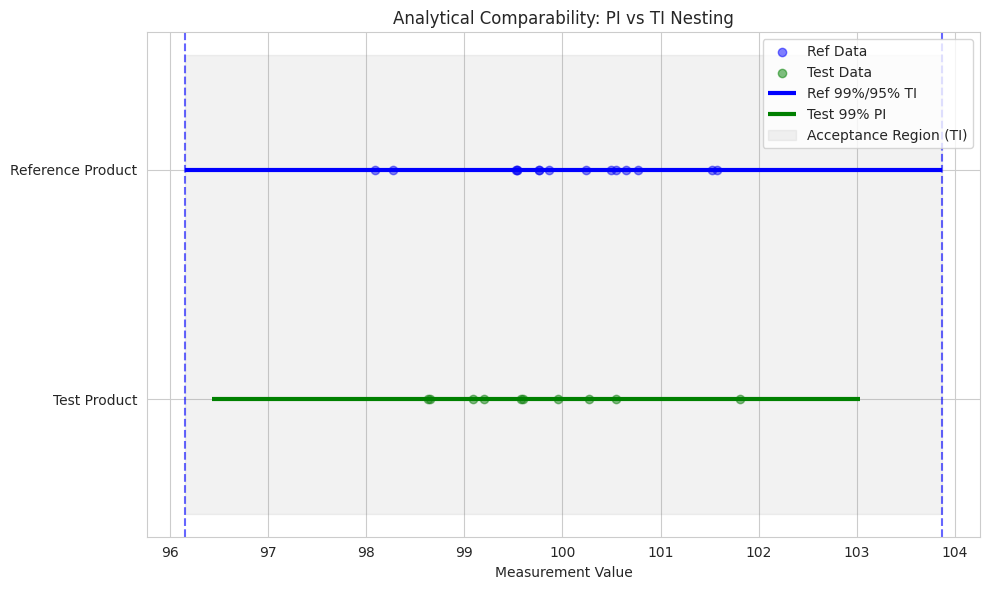

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare data for plotting
plt.figure(figsize=(10, 6))
sns.set_style("whitegrid")

# Plot individual data points
plt.scatter(x_ref, [1] * len(x_ref), alpha=0.5, label='Ref Data', color='blue')
plt.scatter(x_test, [0] * len(x_test), alpha=0.5, label='Test Data', color='green')

# Plot Reference Tolerance Interval
plt.hlines(y=1, xmin=ref_TI[0], xmax=ref_TI[1], colors='blue', linestyles='solid', lw=3, label=f'Ref {int(beta*100)}%/{int(gamma*100)}% TI')
plt.axvline(ref_TI[0], color='blue', linestyle='--', alpha=0.6)
plt.axvline(ref_TI[1], color='blue', linestyle='--', alpha=0.6)

# Plot Test Prediction Interval
plt.hlines(y=0, xmin=test_PI[0], xmax=test_PI[1], colors='green', linestyles='solid', lw=3, label=f'Test {int(beta*100)}% PI')

# Formatting
plt.yticks([0, 1], ['Test Product', 'Reference Product'])
plt.xlabel('Measurement Value')
plt.title('Analytical Comparability: PI vs TI Nesting')

# Highlight the comparison
if is_comparable:
    plt.fill_betweenx([-0.5, 1.5], ref_TI[0], ref_TI[1], color='gray', alpha=0.1, label='Acceptance Region (TI)')

plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

### Sensitivity Analysis
We will now vary $\beta$ (the proportion of the population covered) and $\gamma$ (the confidence level) to see how robust the comparability decision is.

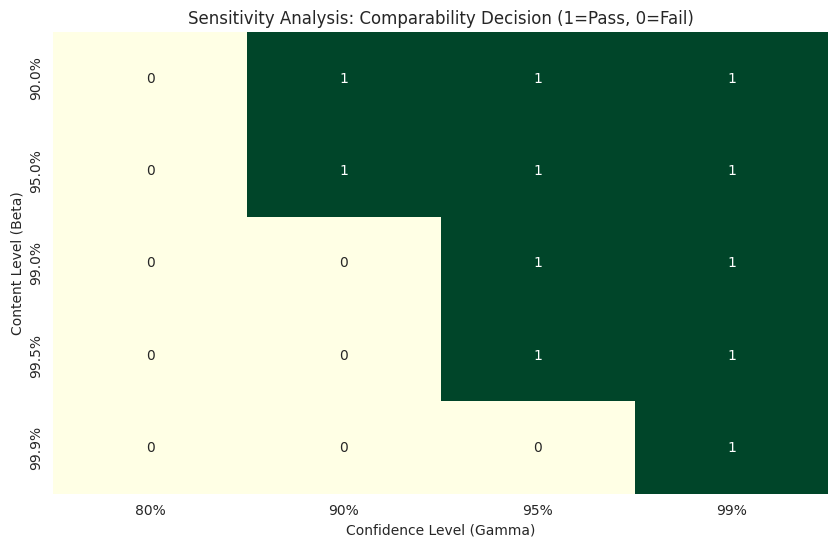

In [ ]:
beta_range = [0.90, 0.95, 0.99, 0.995, 0.999]
gamma_range = [0.80, 0.90, 0.95, 0.99]

# Initialize a matrix to store results
results = np.zeros((len(beta_range), len(gamma_range)))

for i, b in enumerate(beta_range):
    for j, g in enumerate(gamma_range):
        # Calculate intervals for current parameters
        ti_low, ti_high = calc_ref_TI(x_ref, b, g)
        pi_low, pi_high = calc_test_PI(x_test, b)

        # Check nesting
        is_nested = (pi_low >= ti_low) and (pi_high <= ti_high)
        results[i, j] = 1 if is_nested else 0

# Visualize the results
plt.figure(figsize=(10, 6))
sns.heatmap(results, annot=True, cbar=False, cmap='YlGn',
            xticklabels=[f'{int(g*100)}%' for g in gamma_range],
            yticklabels=[f'{b*100}%' for b in beta_range])

plt.title('Sensitivity Analysis: Comparability Decision (1=Pass, 0=Fail)')
plt.xlabel('Confidence Level (Gamma)')
plt.ylabel('Content Level (Beta)')
plt.show()

### Power Analysis: Probability of Success vs. Sample Size
In this section, we simulate the probability of passing the comparability test (nesting PI within TI) for different sample sizes, assuming the underlying distributions are identical.

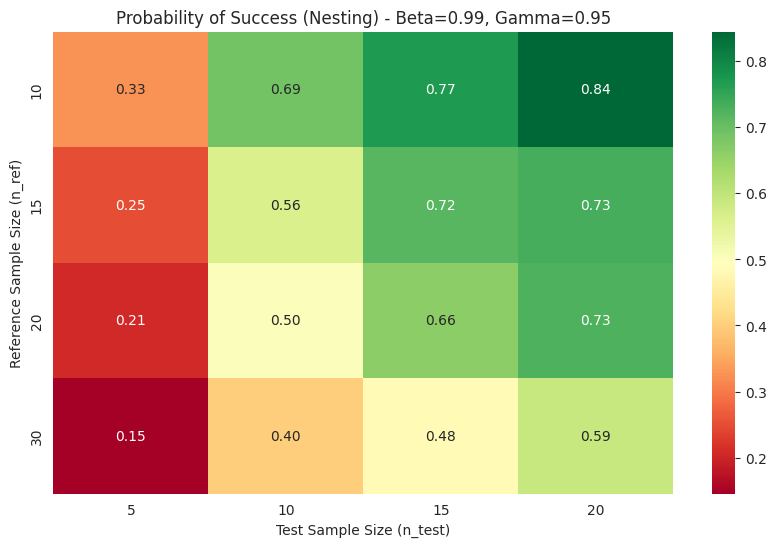

In [ ]:
def simulate_success_rate(n_ref_range, n_test_range, beta=0.99, gamma=0.95, n_sims=500):
    """
    Simulates the probability that the Test PI is nested in the Ref TI
    assuming both products come from the same distribution (N(100, 1)).
    """
    results_matrix = np.zeros((len(n_ref_range), len(n_test_range)))

    for i, nr in enumerate(n_ref_range):
        for j, nt in enumerate(n_test_range):
            successes = 0
            for _ in range(n_sims):
                # Simulate identical distributions
                sim_ref = np.random.normal(100, 1, nr)
                sim_test = np.random.normal(100, 1, nt)

                # Calculate intervals
                ti_l, ti_u = calc_ref_TI(sim_ref, beta, gamma)
                pi_l, pi_u = calc_test_PI(sim_test, beta)

                if (pi_l >= ti_l) and (pi_u <= ti_u):
                    successes += 1
            results_matrix[i, j] = successes / n_sims

    return results_matrix

# Define sample size ranges to test
n_ref_vals = [10, 15, 20, 30]
n_test_vals = [5, 10, 15, 20]

prob_matrix = simulate_success_rate(n_ref_vals, n_test_vals)

# Visualization
plt.figure(figsize=(10, 6))
sns.heatmap(prob_matrix, annot=True, fmt='.2f', cmap='RdYlGn',
            xticklabels=n_test_vals, yticklabels=n_ref_vals)
plt.title(f'Probability of Success (Nesting) - Beta={beta}, Gamma={gamma}')
plt.xlabel('Test Sample Size (n_test)')
plt.ylabel('Reference Sample Size (n_ref)')
plt.show()

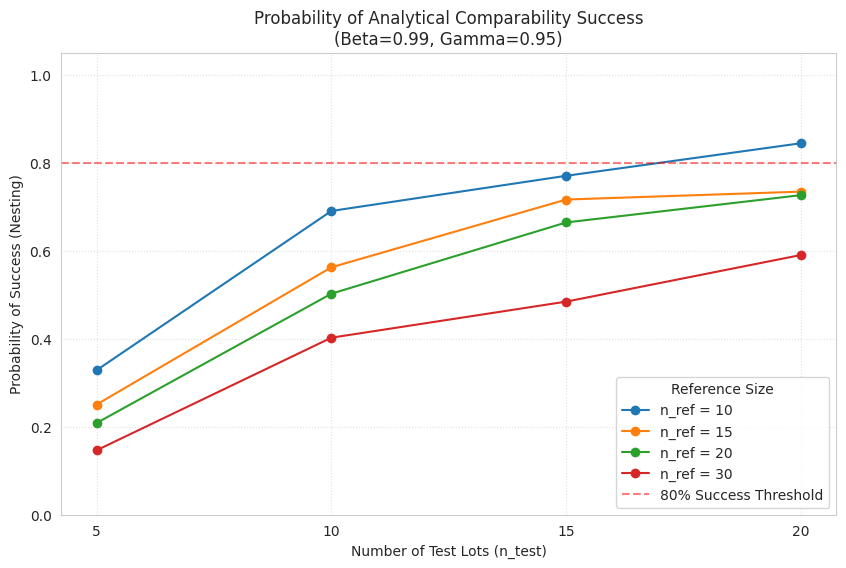

In [ ]:
plt.figure(figsize=(10, 6))

# Plot a line for each Reference Sample Size
for i, nr in enumerate(n_ref_vals):
    plt.plot(n_test_vals, prob_matrix[i, :], marker='o', label=f'n_ref = {nr}')

plt.axhline(y=0.8, color='red', linestyle='--', alpha=0.5, label='80% Success Threshold')

plt.title(f'Probability of Analytical Comparability Success\n(Beta={beta}, Gamma={gamma})')
plt.xlabel('Number of Test Lots (n_test)')
plt.ylabel('Probability of Success (Nesting)')
plt.xticks(n_test_vals)
plt.ylim(0, 1.05)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(title='Reference Size')
plt.show()

### Equivalent R Implementation
Below is the R code to perform the same Tolerance Interval (TI) and Prediction Interval (PI) nesting analysis.

In [ ]:
# Note: This is an R code block. In Colab, you would usually run this in an R kernel
# or use rpy2, but here is the raw R source for your use:

# calc_ref_TI <- function(x_ref, beta, gamma) {
#   n_R <- length(x_ref)
#   mean_R <- mean(x_ref)
#   sd_R <- sd(x_ref)
#
#   z_val <- qnorm((1 + beta) / 2)
#   chi2_val <- qchisq(1 - gamma, df = n_R - 1)
#
#   # Howe's approximation for k_c
#   k_c <- z_val * sqrt((n_R - 1) / chi2_val) * sqrt(1 + 1 / n_R)
#
#   lower <- mean_R - k_c * sd_R
#   upper <- mean_R + k_c * sd_R
#   return(c(lower, upper))
# }
#
# calc_test_PI <- function(x_test, beta) {
#   n_T <- length(x_test)
#   mean_T <- mean(x_test)
#   sd_T <- sd(x_test)
#
#   t_crit <- qt((1 + beta) / 2, df = n_T - 1)
#   margin <- t_crit * sd_T * sqrt(1 + 1 / n_T)
#
#   lower <- mean_T - margin
#   upper <- mean_T + margin
#   return(c(lower, upper))
# }
#
# # Example usage:
# set.seed(42)
# x_ref <- rnorm(15, mean=100, sd=1)
# x_test <- rnorm(10, mean=100.2, sd=1.1)
#
# ti <- calc_ref_TI(x_ref, 0.99, 0.95)
# pi <- calc_test_PI(x_test, 0.99)
#
# is_comparable <- (pi[1] >= ti[1]) && (pi[2] <= ti[2])
# print(paste("Comparability:", is_comparable))

### Bayesian Predictive Credible Interval
Under a non-informative Jeffreys prior $p(\mu, \sigma^2) \propto 1/\sigma^2$, the posterior predictive distribution for a new observation $x_{new}$ follows a Student's t-distribution:

$$x_{new} | \mathbf{x}_{test} \sim t_{n-1}\left(\mu = \bar{x}, \lambda = \frac{n}{s^2(n+1)}\right)$$

where $s$ is the sample standard deviation. The following code calculates the $100\beta\%$ Credible Interval based on this posterior predictive distribution.

In [ ]:
def calc_bayesian_predictive_interval(data, beta):
    """
    Calculates the Bayesian Posterior Predictive Credible Interval
    under a non-informative Jeffreys prior.
    """
    n = len(data)
    x_bar = np.mean(data)
    s = np.std(data, ddof=1)
    df = n - 1

    # The scale factor for the predictive t-distribution
    # equivalent to s * sqrt(1 + 1/n)
    predictive_scale = s * np.sqrt(1 + 1/n)

    # Calculate the bounds using the t-distribution percent point function
    lower, upper = stats.t.interval(beta, df, loc=x_bar, scale=predictive_scale)

    return lower, upper

# Calculate for our existing test data
bayes_PI_low, bayes_PI_high = calc_bayesian_predictive_interval(x_test, beta)

print(f"Bayesian {int(beta*100)}% Credible Interval (Predictive): [{bayes_PI_low:.3f}, {bayes_PI_high:.3f}]")
print(f"Frequentist {int(beta*100)}% Prediction Interval: [{test_PI[0]:.3f}, {test_PI[1]:.3f}]")

# Verification of Duality
if np.allclose([bayes_PI_low, bayes_PI_high], [test_PI[0], test_PI[1]]):
    print("\nIsomorphism Confirmed: The Bayesian Credible Interval matches the Frequentist Prediction Interval.")

Bayesian 99% Credible Interval (Predictive): [96.429, 103.037]
Frequentist 99% Prediction Interval: [96.429, 103.037]

Isomorphism Confirmed: The Bayesian Credible Interval matches the Frequentist Prediction Interval.


### Simulation: Comparing Bayesian vs. Frequentist Intervals
This simulation runs multiple trials to verify that the Bayesian Credible Interval (using a Jeffreys prior) and the Frequentist Prediction Interval always yield the same bounds for any given sample.

Simulation results over 1000 trials:
Maximum difference in interval width: 2.84e-14


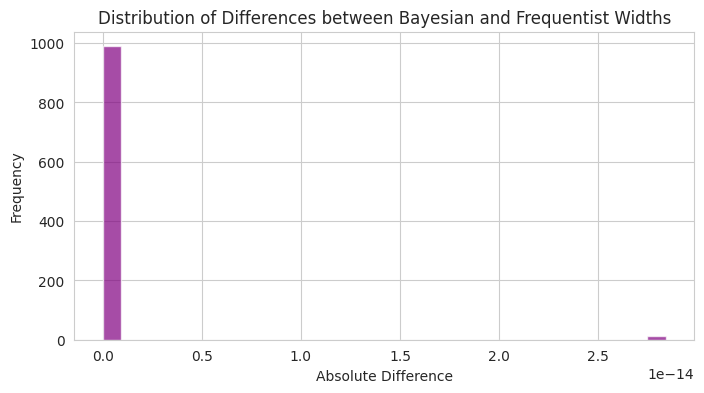

In [ ]:
def run_comparison_simulation(n_trials=1000, sample_size=15, beta=0.99):
    diffs = []

    for _ in range(n_trials):
        # Generate random sample
        sample = np.random.normal(loc=100, scale=1, size=sample_size)

        # Calculate both
        freq_low, freq_high = calc_test_PI(sample, beta)
        bay_low, bay_high = calc_bayesian_predictive_interval(sample, beta)

        # Record absolute difference in interval width
        freq_width = freq_high - freq_low
        bay_width = bay_high - bay_low
        diffs.append(abs(freq_width - bay_width))

    return diffs

sim_diffs = run_comparison_simulation()
max_diff = np.max(sim_diffs)

print(f"Simulation results over 1000 trials:")
print(f"Maximum difference in interval width: {max_diff:.2e}")

plt.figure(figsize=(8, 4))
plt.hist(sim_diffs, bins=30, color='purple', alpha=0.7)
plt.title("Distribution of Differences between Bayesian and Frequentist Widths")
plt.xlabel("Absolute Difference")
plt.ylabel("Frequency")
plt.show()

### Bayesian Informative Prior (Normal-Inverse-Gamma)
When sample sizes are small, we can incorporate historical knowledge using a conjugate prior. For a normal distribution with unknown mean ($\mu$) and variance ($\sigma^2$), the conjugate prior is the Normal-Inverse-Gamma distribution:

- $\mu | \sigma^2 \sim N(\mu_0, \sigma^2/\kappa_0)$
- $\sigma^2 \sim IG(\alpha_0, \beta_0)$

This allows us to 'borrow strength' from historical reference data to calculate the Posterior Predictive distribution.

In [ ]:
def calc_informative_bayesian_pi(data, prior_params, beta):
    """
    Calculates the Credible Interval using a Normal-Inverse-Gamma prior.
    prior_params: dict with keys 'mu0', 'kappa0', 'alpha0', 'beta0'
    """
    n = len(data)
    x_bar = np.mean(data)
    s2 = np.var(data, ddof=1) if n > 1 else 0

    # Update parameters to Posterior values
    kappa_n = prior_params['kappa0'] + n
    mu_n = (prior_params['kappa0'] * prior_params['mu0'] + n * x_bar) / kappa_n
    alpha_n = prior_params['alpha0'] + n/2

    # Sum of squares update
    ss = np.sum((data - x_bar)**2) if n > 1 else 0
    beta_n = prior_params['beta0'] + 0.5 * ss + \
             (n * prior_params['kappa0'] * (x_bar - prior_params['mu0'])**2) / (2 * kappa_n)

    # The Posterior Predictive is a t-distribution:
    df_post = 2 * alpha_n
    loc_post = mu_n
    # Scale for predictive distribution
    scale_post = np.sqrt((beta_n * (kappa_n + 1)) / (alpha_n * kappa_n))

    lower, upper = stats.t.interval(beta, df=df_post, loc=loc_post, scale=scale_post)
    return lower, upper

# --- Scenario: Very small sample size (n=3) ---
small_test_data = np.random.normal(100, 1, 3)

# Informative Prior based on historical knowledge (Mean=100, SD=1)
historical_prior = {
    'mu0': 100,
    'kappa0': 10, # equivalent to having observed 10 historical samples for the mean
    'alpha0': 5,  # shape for variance
    'beta0': 5    # scale for variance (alpha/beta relates to expected variance)
}

inf_low, inf_high = calc_informative_bayesian_pi(small_test_data, historical_prior, 0.99)
non_inf_low, non_inf_high = calc_bayesian_predictive_interval(small_test_data, 0.99)

print(f"Results for n=3 samples:")
print(f"Non-informative Interval: [{non_inf_low:.3f}, {non_inf_high:.3f}] (Width: {non_inf_high-non_inf_low:.2f})")
print(f"Informative Prior Interval: [{inf_low:.3f}, {inf_high:.3f}] (Width: {inf_high-inf_low:.2f})")

Results for n=3 samples:
Non-informative Interval: [88.236, 111.488] (Width: 23.25)
Informative Prior Interval: [96.952, 102.984] (Width: 6.03)


### Visualizing Prior Strength ($\kappa_0$)
The parameter $\kappa_0$ in our Normal-Inverse-Gamma prior represents how many 'pseudo-observations' the historical data is worth. A higher $\kappa_0$ means we are more certain about our prior mean, leading to a narrower and more stable Credible Interval.

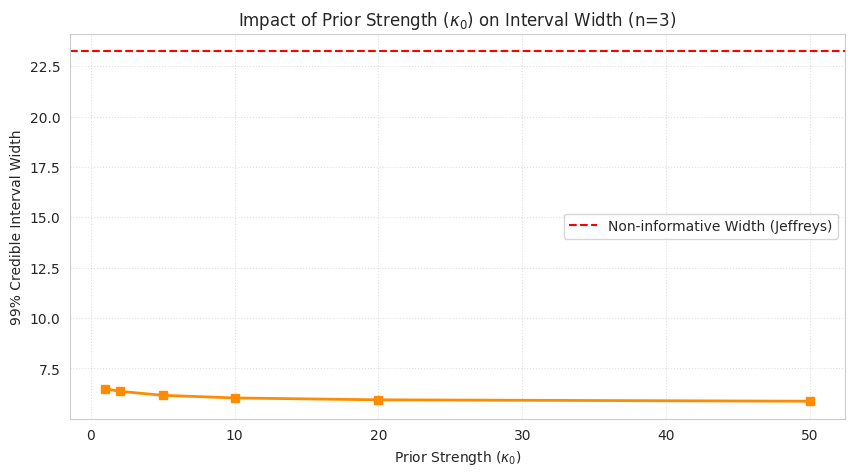

In [ ]:
kappa_values = [1, 2, 5, 10, 20, 50]
widths = []

# We use the same small sample (n=3) from before
for k in kappa_values:
    temp_prior = {
        'mu0': 100,
        'kappa0': k,
        'alpha0': 5,
        'beta0': 5
    }
    l, u = calc_informative_bayesian_pi(small_test_data, temp_prior, 0.99)
    widths.append(u - l)

plt.figure(figsize=(10, 5))
plt.plot(kappa_values, widths, marker='s', color='darkorange', linewidth=2)
plt.axhline(y=non_inf_high - non_inf_low, color='red', linestyle='--', label='Non-informative Width (Jeffreys)')

plt.title('Impact of Prior Strength ($\\kappa_0$) on Interval Width (n=3)')
plt.xlabel('Prior Strength ($\\kappa_0$)')
plt.ylabel('99% Credible Interval Width')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.show()

### Sample Size vs. Interval Width: Informative Prior Dynamics
This simulation examines the convergence of interval widths. We compare a non-informative prior against informative priors with varying degrees of strength ($\kappa_0$) across a range of sample sizes ($n=2$ to $n=50$).

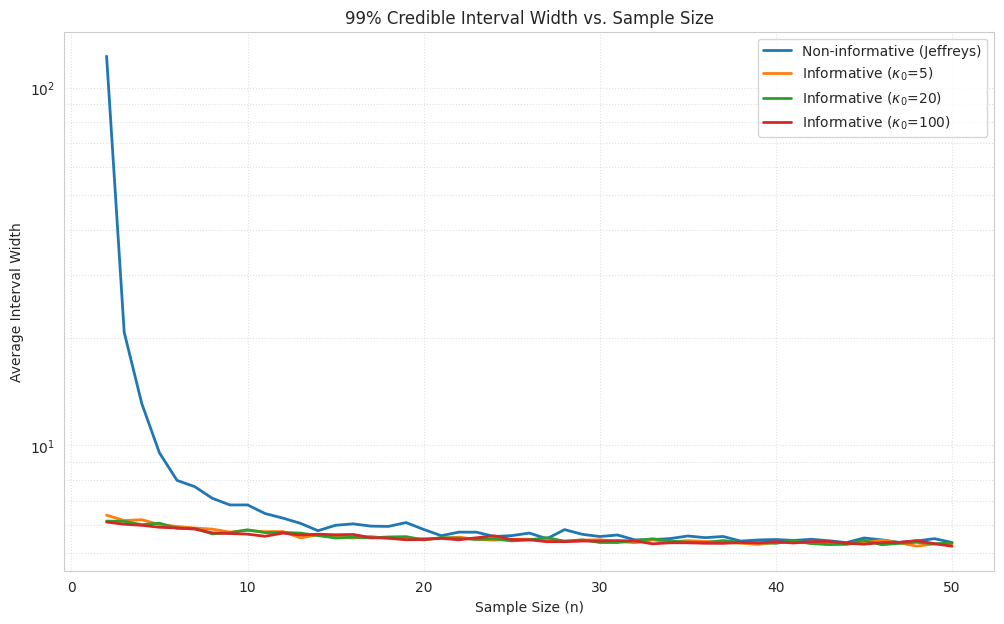

In [ ]:
sample_sizes = np.arange(2, 51)
kappa_to_test = [0, 5, 20, 100] # 0 will represent the non-informative case

plt.figure(figsize=(12, 7))

for k in kappa_to_test:
    avg_widths = []
    for n in sample_sizes:
        # Simulate multiple trials to get a stable average width
        trial_widths = []
        for _ in range(100):
            data = np.random.normal(100, 1, n)
            if k == 0:
                l, u = calc_bayesian_predictive_interval(data, 0.99)
            else:
                prior = {'mu0': 100, 'kappa0': k, 'alpha0': 5, 'beta0': 5}
                l, u = calc_informative_bayesian_pi(data, prior, 0.99)
            trial_widths.append(u - l)
        avg_widths.append(np.mean(trial_widths))

    label = 'Non-informative (Jeffreys)' if k == 0 else f'Informative ($\\kappa_0$={k})'
    plt.plot(sample_sizes, avg_widths, label=label, linewidth=2)

plt.title('99% Credible Interval Width vs. Sample Size')
plt.xlabel('Sample Size (n)')
plt.ylabel('Average Interval Width')
plt.yscale('log') # Log scale helps see the differences at small n
plt.grid(True, which='both', linestyle=':', alpha=0.6)
plt.legend()
plt.show()

### Sensitivity to Prior Mean ($\mu_0$)
In this analysis, we examine how sensitive the result is to our historical assumptions. We vary the prior mean from 95 to 105 (centered around the observed data near 100) to see how the posterior predictive interval reacts.

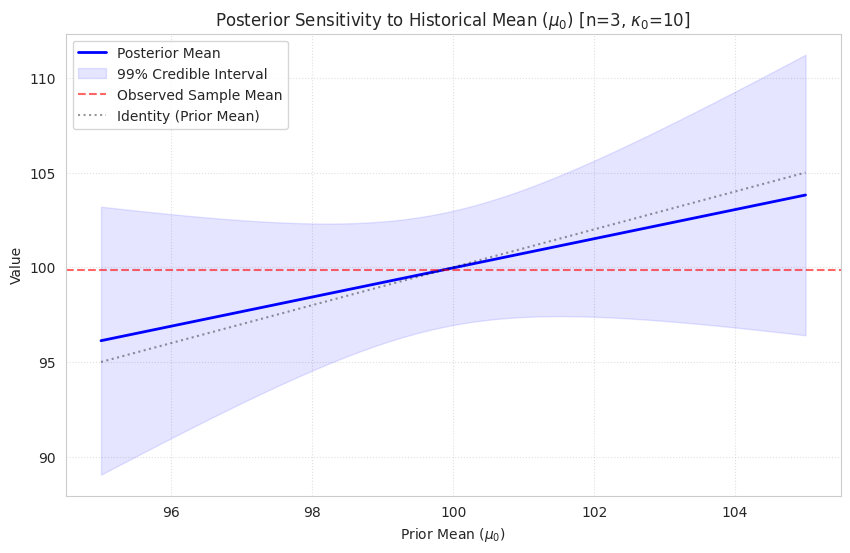

In [ ]:
mu0_values = np.linspace(95, 105, 50)
posterior_means = []
lower_bounds = []
upper_bounds = []

# Using the fixed small_test_data (n=3) and a moderate prior strength (kappa0=10)
kappa0_fixed = 10

for m in mu0_values:
    prior = {'mu0': m, 'kappa0': kappa0_fixed, 'alpha0': 5, 'beta0': 5}
    l, u = calc_informative_bayesian_pi(small_test_data, prior, 0.99)

    # The posterior mean is a weighted average of prior mean and sample mean
    n = len(small_test_data)
    post_mean = (kappa0_fixed * m + n * np.mean(small_test_data)) / (kappa0_fixed + n)

    posterior_means.append(post_mean)
    lower_bounds.append(l)
    upper_bounds.append(u)

plt.figure(figsize=(10, 6))
plt.plot(mu0_values, posterior_means, label='Posterior Mean', color='blue', lw=2)
plt.fill_between(mu0_values, lower_bounds, upper_bounds, color='blue', alpha=0.1, label='99% Credible Interval')
plt.axhline(y=np.mean(small_test_data), color='red', linestyle='--', alpha=0.6, label='Observed Sample Mean')
plt.plot(mu0_values, mu0_values, color='black', linestyle=':', alpha=0.4, label='Identity (Prior Mean)')

plt.title(f'Posterior Sensitivity to Historical Mean ($\\mu_0$) [n=3, $\\kappa_0$={kappa0_fixed}]')
plt.xlabel('Prior Mean ($\\mu_0$)')
plt.ylabel('Value')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

### Influence of Prior Variance Assumption ($\beta_0$)
The $\beta_0$ parameter in the Normal-Inverse-Gamma prior acts as a scale factor for the variance. Higher $\beta_0$ values suggest a prior belief in higher volatility, which will expand the predictive interval.

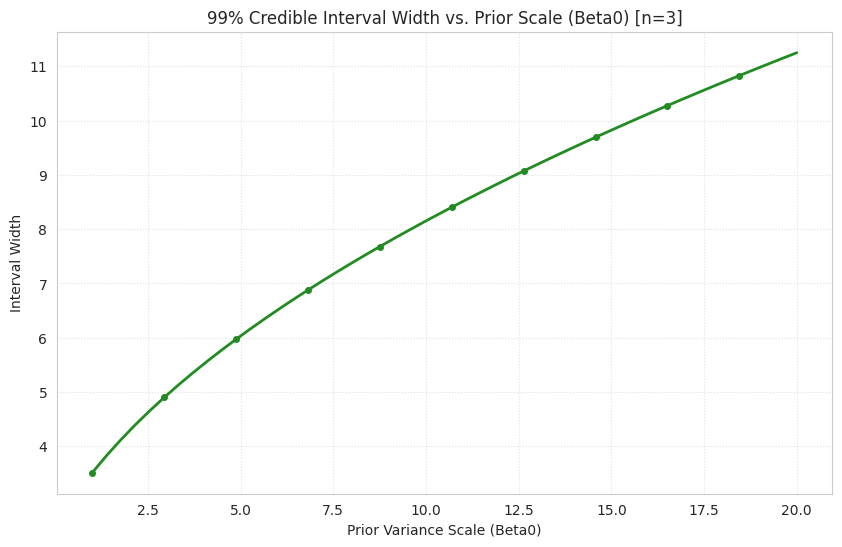

In [ ]:
beta0_values = np.linspace(1, 20, 50)
interval_widths = []

# Using fixed small_test_data (n=3), fixed mu0=100, and fixed kappa0=10
for b0 in beta0_values:
    prior = {'mu0': 100, 'kappa0': 10, 'alpha0': 5, 'beta0': b0}
    l, u = calc_informative_bayesian_pi(small_test_data, prior, 0.99)
    interval_widths.append(u - l)

plt.figure(figsize=(10, 6))
plt.plot(beta0_values, interval_widths, color='forestgreen', lw=2, marker='o', markersize=4, markevery=5)

# Simplified titles to avoid Matplotlib mathtext parser issues
plt.title('99% Credible Interval Width vs. Prior Scale (Beta0) [n=3]')
plt.xlabel('Prior Variance Scale (Beta0)')
plt.ylabel('Interval Width')
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

### Convergence of the Posterior Mean
This simulation demonstrates how the Posterior Mean moves from the Prior Mean ($\mu_0$) toward the Sample Mean ($\bar{x}$) as the sample size $n$ increases. This is a visual representation of the Bayesian 'learning' process.

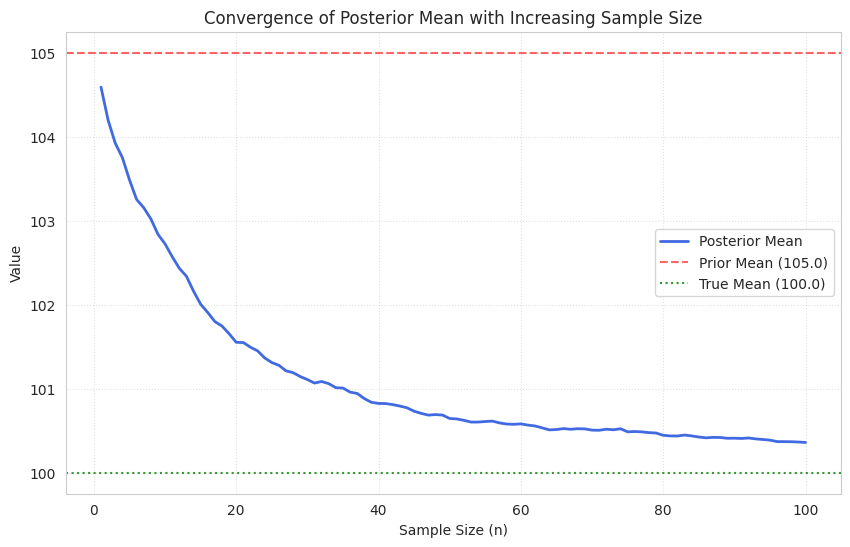

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
prior_mu = 105.0  # Deliberately biased prior
observed_mu = 100.0 # True underlying population mean
kappa0 = 10       # Prior strength
sample_sizes = np.arange(1, 101)

# Generate a large pool of data
np.random.seed(42)
all_data = np.random.normal(loc=observed_mu, scale=1.0, size=max(sample_sizes))

post_means = []

for n in sample_sizes:
    current_data = all_data[:n]
    x_bar = np.mean(current_data)

    # Bayesian Posterior Mean formula for Normal-Inverse-Gamma
    # mu_n = (kappa0 * mu0 + n * x_bar) / (kappa0 + n)
    mu_n = (kappa0 * prior_mu + n * x_bar) / (kappa0 + n)
    post_means.append(mu_n)

# Plotting
plt.figure(figsize=(10, 6))
plt.plot(sample_sizes, post_means, label='Posterior Mean', color='royalblue', lw=2)
plt.axhline(y=prior_mu, color='red', linestyle='--', alpha=0.6, label=f'Prior Mean ({prior_mu})')
plt.axhline(y=observed_mu, color='green', linestyle=':', alpha=0.8, label=f'True Mean ({observed_mu})')

plt.title('Convergence of Posterior Mean with Increasing Sample Size')
plt.xlabel('Sample Size (n)')
plt.ylabel('Value')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

### Quantifying the 'Effective $n_R$'
In this section, we determine how many frequentist samples our Bayesian Informative Prior is worth. By matching the width of the Bayesian interval (at $n=3$) to frequentist Tolerance Intervals of increasing $n_R$, we can visualize the 'boost' in statistical power.

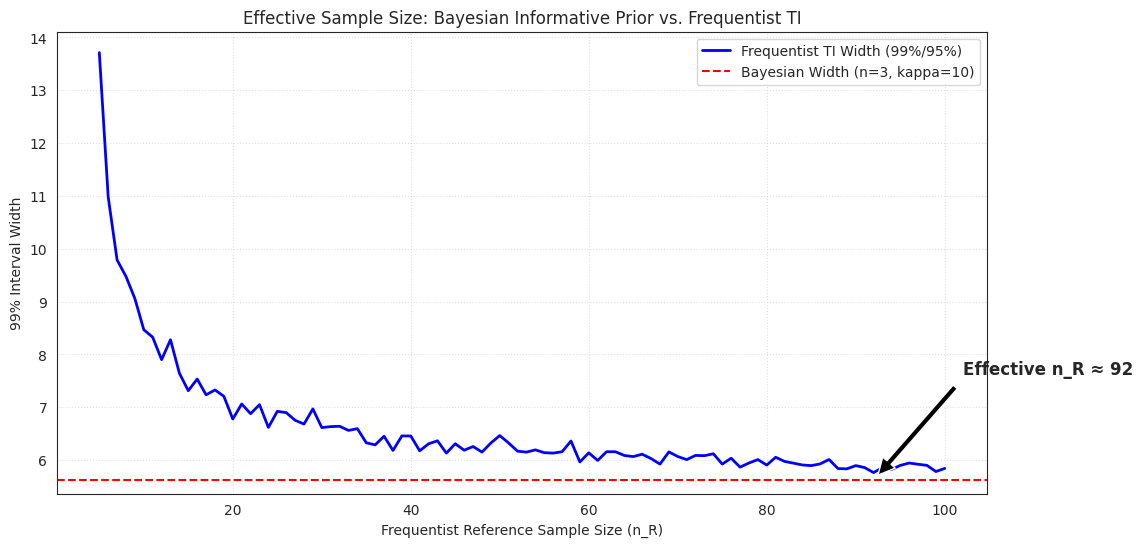

The Bayesian method with n=3 and kappa_0=10 provides the same precision as a frequentist sample of n_R ≈ 92.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Calculate the width of our Bayesian Informative Interval (n=3, kappa=10)
sample_n3 = np.array([99.5, 100.0, 100.5])
prior_k10 = {'mu0': 100, 'kappa0': 10, 'alpha0': 5, 'beta0': 5}
bayes_low, bayes_high = calc_informative_bayesian_pi(sample_n3, prior_k10, 0.99)
bayes_width = bayes_high - bayes_low

# 2. Calculate widths of standard Frequentist TIs for a range of n_ref
n_ref_range = np.arange(5, 101)
freq_ti_widths = []

for nr in n_ref_range:
    widths = []
    for _ in range(50):
        sim_ref = np.random.normal(100, 1, nr)
        l, u = calc_ref_TI(sim_ref, 0.99, 0.95)
        widths.append(u - l)
    freq_ti_widths.append(np.mean(widths))

# 3. Visualization
plt.figure(figsize=(12, 6))
plt.plot(n_ref_range, freq_ti_widths, label='Frequentist TI Width (99%/95%)', color='blue', lw=2)
plt.axhline(y=bayes_width, color='red', linestyle='--', label='Bayesian Width (n=3, kappa=10)')

# Find the intersection (Effective n_R)
eff_nr = n_ref_range[np.argmin(np.abs(np.array(freq_ti_widths) - bayes_width))]

# Fixed the annotation string by using a raw string and escaping backslashes
plt.annotate(f'Effective n_R ≈ {eff_nr}',
             xy=(eff_nr, bayes_width), xytext=(eff_nr+10, bayes_width+2),
             arrowprops=dict(facecolor='black', shrink=0.05), fontsize=12, fontweight='bold')

plt.title('Effective Sample Size: Bayesian Informative Prior vs. Frequentist TI')
plt.xlabel('Frequentist Reference Sample Size (n_R)')
plt.ylabel('99% Interval Width')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.show()

print(f"The Bayesian method with n=3 and kappa_0=10 provides the same precision as a frequentist sample of n_R ≈ {eff_nr}.")

Comparing methods for n_ref = 30...


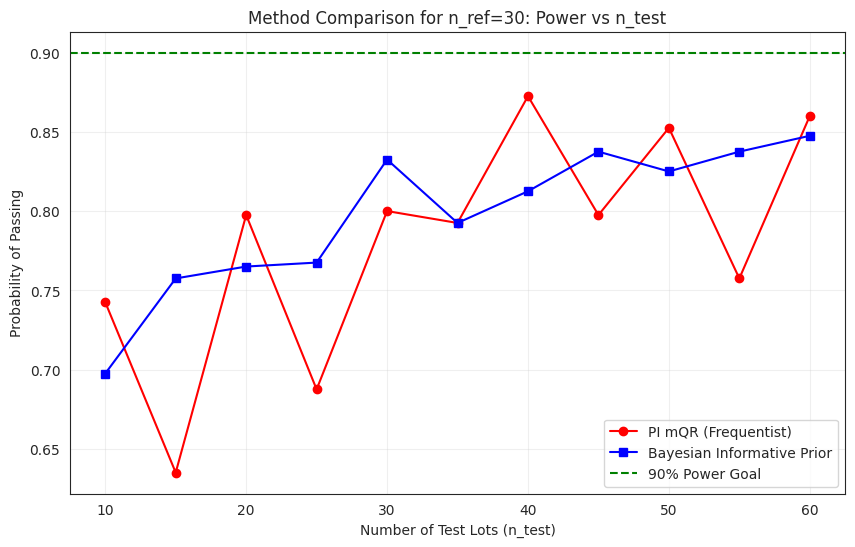

In [ ]:
def compare_bayesian_vs_pi_mqr(n_ref=30, n_test_range=range(10, 61, 5), n_sims=400):
    # Prior params representing strong historical knowledge (kappa=10)
    prior = {'mu0': 100, 'kappa0': 10, 'alpha0': 5, 'beta0': 5}

    results = {'PI_mQR': [], 'Bayesian_Informative': []}

    print(f"Comparing methods for n_ref = {n_ref}...")

    for nt in n_test_range:
        pass_pi = 0
        pass_bayes = 0

        for _ in range(n_sims):
            sim_ref = np.random.normal(100, 1, n_ref)
            sim_test = np.random.normal(100, 1, nt)

            # 1. PI mQR Evaluation
            res_pi = evaluate_similarity(sim_ref, sim_test, method='PI_mQR')
            if res_pi['Decision'] == 'PASS':
                pass_pi += 1

            # 2. Bayesian Informative Evaluation
            # Rule: Test PI (Informative) must fit within Ref TI (Standard 99/95)
            ref_l, ref_u = calc_ref_TI(sim_ref, 0.99, 0.95)
            test_l, test_u = calc_informative_bayesian_pi(sim_test, prior, 0.99)

            if (test_l >= ref_l) and (test_u <= ref_u):
                pass_bayes += 1

        results['PI_mQR'].append(pass_pi / n_sims)
        results['Bayesian_Informative'].append(pass_bayes / n_sims)

    # Plotting
    plt.figure(figsize=(10, 6))
    plt.plot(n_test_range, results['PI_mQR'], label='PI mQR (Frequentist)', marker='o', color='red')
    plt.plot(n_test_range, results['Bayesian_Informative'], label='Bayesian Informative Prior', marker='s', color='blue')
    plt.axhline(y=0.90, color='green', linestyle='--', label='90% Power Goal')

    plt.title(f'Method Comparison for n_ref={n_ref}: Power vs n_test')
    plt.xlabel('Number of Test Lots (n_test)')
    plt.ylabel('Probability of Passing')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

compare_bayesian_vs_pi_mqr()

In [ ]:
def find_min_n_test_bayesian(target_power=0.90, n_ref_range=[15, 30, 60], prior_kappa=10, max_n=100, n_sims=500):
    """
    Finds the minimum n_test required to reach target power using the Bayesian Informative Prior method.
    Prior assumes mean=100, SD=1.
    """
    prior = {'mu0': 100, 'kappa0': prior_kappa, 'alpha0': 5, 'beta0': 5}
    results = {}

    print(f"Searching for min n_test (Bayesian, kappa={prior_kappa}) to reach {target_power*100}% power...")

    for nr in n_ref_range:
        found = False
        # We start search from n=3 as Bayesian can handle very small samples
        for nt in range(3, max_n + 1):
            successes = 0
            for _ in range(n_sims):
                sim_ref = np.random.normal(100, 1, nr)
                sim_test = np.random.normal(100, 1, nt)

                # Standard frequentist TI for reference goalposts
                ref_l, ref_u = calc_ref_TI(sim_ref, 0.99, 0.95)
                # Bayesian informative PI for test product
                test_l, test_u = calc_informative_bayesian_pi(sim_test, prior, 0.99)

                if (test_l >= ref_l) and (test_u <= ref_u):
                    successes += 1

            power = successes / n_sims
            if power >= target_power:
                results[nr] = (nt, power)
                print(f"  -> For n_ref={nr}: Min n_test = {nt} ({power:.1%} power)")
                found = True
                break

        if not found:
            results[nr] = (None, None)
            print(f"  -> For n_ref={nr}: Could not reach target power within n_test={max_n}")

    return results

# Run the search for the Bayesian method
bayes_min_samples = find_min_n_test_bayesian(prior_kappa=10)

Searching for min n_test (Bayesian, kappa=10) to reach 90.0% power...
  -> For n_ref=15: Min n_test = 47 (90.6% power)
  -> For n_ref=30: Could not reach target power within n_test=100
  -> For n_ref=60: Could not reach target power within n_test=100


In [ ]:
import numpy as np
from scipy import stats
from scipy.optimize import root_scalar

def evaluate_similarity(x_ref, x_test, method="QR", inclusion_thresh=0.90):
    """
    Evaluate Analytical Similarity using QR or mQR Methods.
    """
    n_R = len(x_ref)
    n_T = len(x_test)
    mean_R = np.mean(x_ref)
    sd_R = np.std(x_ref, ddof=1)
    mean_T = np.mean(x_test)
    sd_T = np.std(x_test, ddof=1)

    sd_ratio = sd_T / sd_R
    mean_diff = mean_T - mean_R

    # Preliminary Check: Similarity of Standard Deviations (Method 1)
    sd_similar = (2/3 < sd_ratio < 3/2)

    lower_bound = np.nan
    upper_bound = np.nan
    M_val = np.nan

    if method == "QR":
        # Standard Quality Range Method (k = 3)
        k = 3.0
        lower_bound = mean_R - k * sd_R
        upper_bound = mean_R + k * sd_R

    elif method == "ES_mQR":
        # Effect Size Modified QR
        k_base = 2.23
        # Condition 1: Mean shift <= 1/8 sd_R
        # Condition 2: SD ratio within (2/3, 3/2)
        if abs(mean_diff) <= (1/8) * sd_R and sd_similar:
            k = k_base
        else:
            # Apply Effect Size adjustment: k_adj = k - (C - 1)
            C = sd_ratio
            k = k_base - (C - 1)
            if k <= 0:
                k = 0.01 # Prevent negative bounds

        lower_bound = mean_R - k * sd_R
        upper_bound = mean_R + k * sd_R

    elif method == "PI_mQR":
        # Plausibility Integral Modified QR
        a = 3.0
        alpha = 0.05

        # Preliminary Step 1: Check if 95% CI of difference is within Plausibility Interval
        se_diff = np.sqrt(sd_R**2 / n_R + sd_T**2 / n_T)
        t_crit = stats.t.ppf(1 - alpha/2, df=n_R + n_T - 2)
        ci_diff_lower = mean_diff - t_crit * se_diff
        ci_diff_upper = mean_diff + t_crit * se_diff

        pi_lower = -a * sd_R
        pi_upper = a * sd_R

        ti_within_pi = (ci_diff_lower >= pi_lower) and (ci_diff_upper <= pi_upper)

        if ti_within_pi:
            P_target = 1 - alpha
            d_val = 0.0
        else:
            P_target = alpha
            d_val = (mean_R - mean_T) / sd_T

        r_val = sd_R / sd_T

        # Define the integral function f(M) = Phi(d + M*r) - Phi(d - M*r)
        def f_M(M):
            return stats.norm.cdf(d_val + M * r_val) - stats.norm.cdf(d_val - M * r_val)

        # Solve for M: f(M) - P_target = 0
        def objective(M):
            return f_M(M) - P_target

        res = root_scalar(objective, bracket=[0, 10], method='brentq')
        if res.converged:
            M_val = res.root
        else:
            raise ValueError("Root finding for PI mQR failed to converge.")

        # Preliminary Step 2: Variance Asymmetry Penalty
        if sd_R > sd_T:
            scale_factor = sd_T
        elif sd_ratio >= 1.5:
            scale_factor = sd_R
        else:
            scale_factor = sd_R

        lower_bound = mean_R - M_val * scale_factor
        upper_bound = mean_R + M_val * scale_factor

    # Calculate proportion of test lots within the calculated range
    in_range = np.sum((x_test >= lower_bound) & (x_test <= upper_bound)) / n_T
    decision = "PASS" if in_range >= inclusion_thresh else "FAIL"

    return {
        "Method": method,
        "Decision": decision,
        "Inclusion_Proportion": round(float(in_range), 4),
        "Lower_Bound": round(float(lower_bound), 4),
        "Upper_Bound": round(float(upper_bound), 4),
        "M_Factor (PI only)": round(float(M_val), 4) if method == "PI_mQR" else "N/A",
        "SD_Ratio": round(float(sd_ratio), 4),
        "Mean_Diff": round(float(mean_diff), 4),
        "SD_Similar": sd_similar
    }

# ==========================================
# Example Execution
# ==========================================
np.random.seed(123)
x_ref = np.random.normal(loc=100, scale=1.0, size=15)
x_test = np.random.normal(loc=101.5, scale=1.4, size=10)

for method in ["QR", "ES_mQR", "PI_mQR"]:
    print(f"\n--- {method} Method ---")
    res_dict = evaluate_similarity(x_ref, x_test, method=method)
    for k, v in res_dict.items():
        print(f"{k}: {v}")


--- QR Method ---
Method: QR
Decision: FAIL
Inclusion_Proportion: 0.7
Lower_Bound: 96.3301
Upper_Bound: 103.2619
M_Factor (PI only): N/A
SD_Ratio: 1.4722
Mean_Diff: 2.6228
SD_Similar: True

--- ES_mQR Method ---
Method: ES_mQR
Decision: FAIL
Inclusion_Proportion: 0.3
Lower_Bound: 97.7652
Upper_Bound: 101.8267
M_Factor (PI only): N/A
SD_Ratio: 1.4722
Mean_Diff: 2.6228
SD_Similar: True

--- PI_mQR Method ---
Method: PI_mQR
Decision: FAIL
Inclusion_Proportion: 0.1
Lower_Bound: 99.4493
Upper_Bound: 100.1427
M_Factor (PI only): 0.3001
SD_Ratio: 1.4722
Mean_Diff: 2.6228
SD_Similar: True


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.optimize import root_scalar

def evaluate_similarity(x_ref, x_test, method="QR", inclusion_thresh=0.90):
    n_R, n_T = len(x_ref), len(x_test)
    mean_R, sd_R = np.mean(x_ref), np.std(x_ref, ddof=1)
    mean_T, sd_T = np.mean(x_test), np.std(x_test, ddof=1)
    sd_ratio = sd_T / sd_R
    mean_diff = mean_T - mean_R
    sd_similar = (2/3 < sd_ratio < 3/2)

    if method == "QR":
        k = 3.0
        lower_bound, upper_bound = mean_R - k * sd_R, mean_R + k * sd_R
    elif method == "ES_mQR":
        k_base = 2.23
        k = k_base if (abs(mean_diff) <= (1/8) * sd_R and sd_similar) else max(0.01, k_base - (sd_ratio - 1))
        lower_bound, upper_bound = mean_R - k * sd_R, mean_R + k * sd_R
    elif method == "PI_mQR":
        a, alpha = 3.0, 0.05
        se_diff = np.sqrt(sd_R**2 / n_R + sd_T**2 / n_T)
        t_crit = stats.t.ppf(1 - alpha/2, df=n_R + n_T - 2)
        ti_within_pi = (mean_diff - t_crit * se_diff >= -a * sd_R) and (mean_diff + t_crit * se_diff <= a * sd_R)
        P_target, d_val = (1 - alpha, 0.0) if ti_within_pi else (alpha, (mean_R - mean_T) / sd_T)
        r_val = sd_R / sd_T
        res = root_scalar(lambda M: (stats.norm.cdf(d_val + M * r_val) - stats.norm.cdf(d_val - M * r_val)) - P_target, bracket=[0, 10], method='brentq')
        M_val = res.root
        scale_factor = sd_T if sd_R > sd_T else sd_R
        lower_bound, upper_bound = mean_R - M_val * scale_factor, mean_R + M_val * scale_factor

    in_range = np.sum((x_test >= lower_bound) & (x_test <= upper_bound)) / n_T
    return {
        "Method": method,
        "Decision": "PASS" if in_range >= inclusion_thresh else "FAIL",
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Inclusion_Proportion": in_range
    }

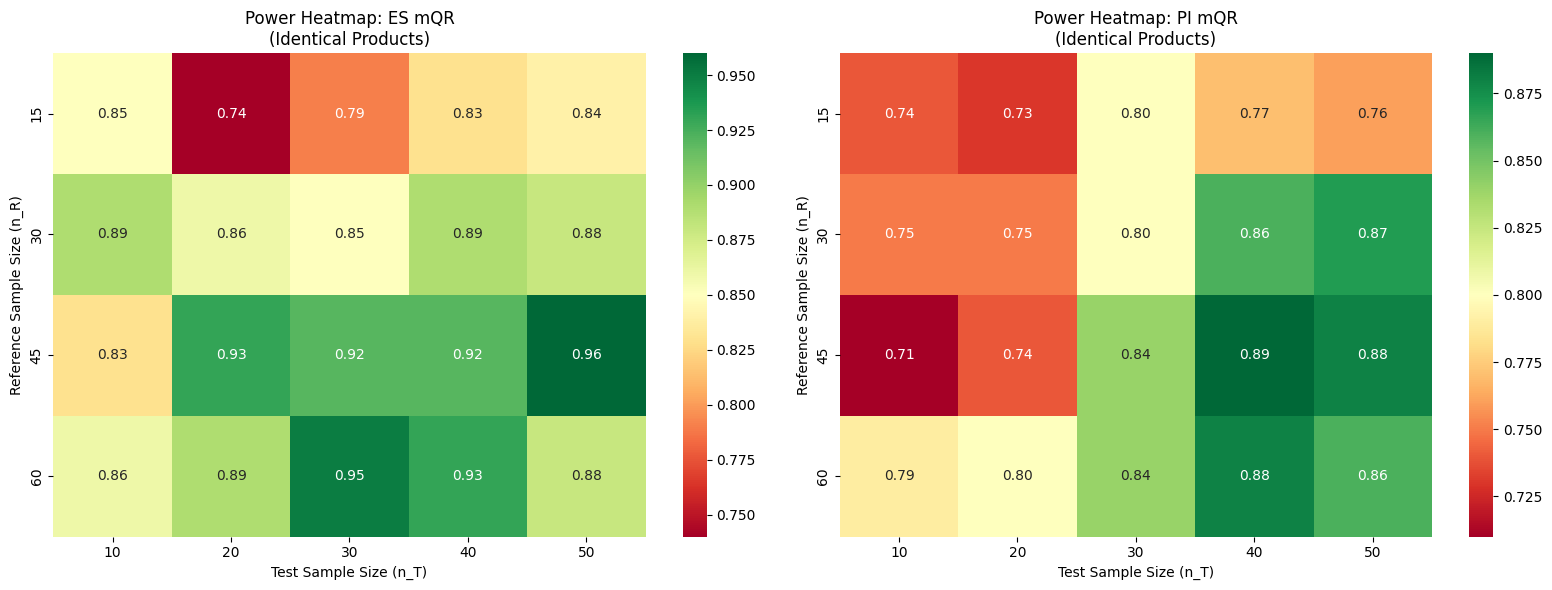

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Heatmap for ES mQR
sns.heatmap(power_es, annot=True, fmt='.2f', cmap='RdYlGn', ax=ax1,
            xticklabels=n_test_grid, yticklabels=n_ref_grid)
ax1.set_title('Power Heatmap: ES mQR\n(Identical Products)')
ax1.set_xlabel('Test Sample Size (n_T)')
ax1.set_ylabel('Reference Sample Size (n_R)')

# Heatmap for PI mQR
sns.heatmap(power_pi, annot=True, fmt='.2f', cmap='RdYlGn', ax=ax2,
            xticklabels=n_test_grid, yticklabels=n_ref_grid)
ax2.set_title('Power Heatmap: PI mQR\n(Identical Products)')
ax2.set_xlabel('Test Sample Size (n_T)')
ax2.set_ylabel('Reference Sample Size (n_R)')

plt.tight_layout()
plt.show()

### Visualizing mQR and PI mQR Acceptance Regions
This plot compares the acceptance boundaries generated by the three methods. Note how the **PI mQR** and **ES mQR** boundaries react to the inflated variance and mean shift of the test product compared to the standard **Quality Range (k=3)**.

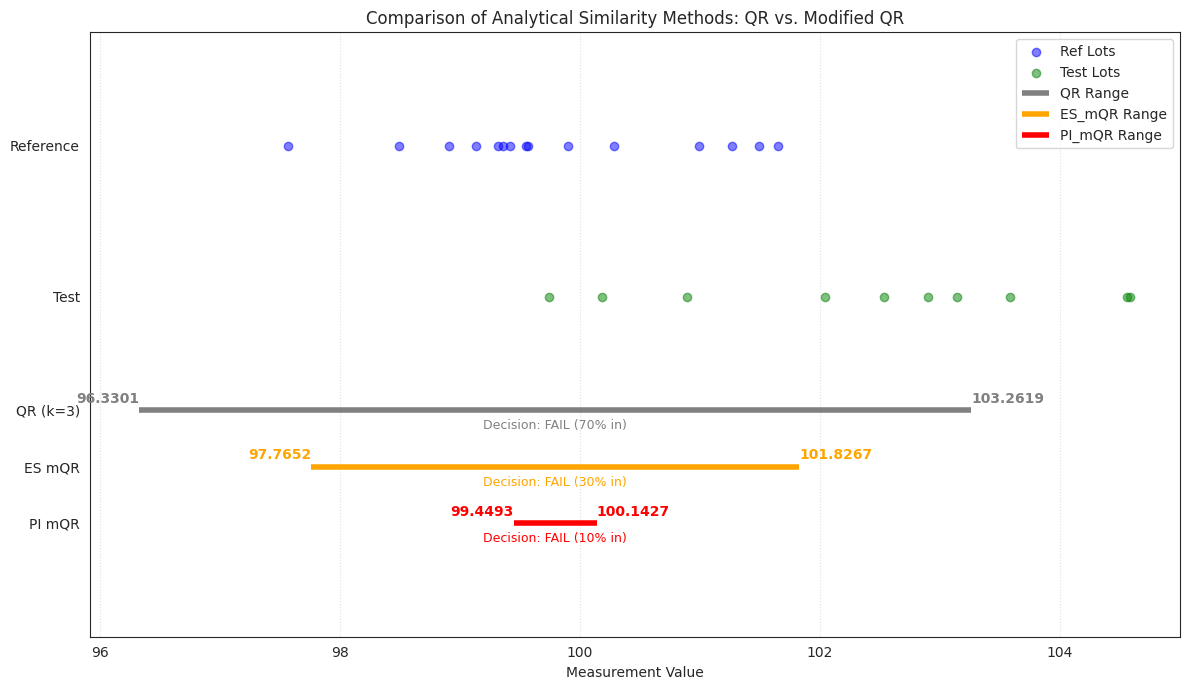

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Run evaluations for the current simulation data
methods = ["QR", "ES_mQR", "PI_mQR"]
results_list = [evaluate_similarity(x_ref, x_test, method=m) for m in methods]

plt.figure(figsize=(12, 7))
sns.set_style("white")

# Plot Data Points
plt.scatter(x_ref, [1.2]*len(x_ref), color='blue', alpha=0.5, label='Ref Lots', zorder=3)
plt.scatter(x_test, [0.8]*len(x_test), color='green', alpha=0.5, label='Test Lots', zorder=3)

# Colors for the methods
colors = {'QR': 'gray', 'ES_mQR': 'orange', 'PI_mQR': 'red'}

# Plot the bounds for each method
for i, res in enumerate(results_list):
    m_name = res['Method']
    lb, ub = res['Lower_Bound'], res['Upper_Bound']
    y_pos = 0.5 - (i * 0.15)

    plt.hlines(y=y_pos, xmin=lb, xmax=ub, color=colors[m_name], lw=4, label=f"{m_name} Range")
    plt.text(lb, y_pos + 0.02, f"{lb}", color=colors[m_name], fontweight='bold', ha='right')
    plt.text(ub, y_pos + 0.02, f"{ub}", color=colors[m_name], fontweight='bold', ha='left')

    # Indicate Pass/Fail
    plt.text((lb+ub)/2, y_pos - 0.05, f"Decision: {res['Decision']} ({int(res['Inclusion_Proportion']*100)}% in)",
             color=colors[m_name], ha='center', fontsize=9)

plt.yticks([1.2, 0.8, 0.5, 0.35, 0.2], ['Reference', 'Test', 'QR (k=3)', 'ES mQR', 'PI mQR'])
plt.ylim(-0.1, 1.5)
plt.xlabel("Measurement Value")
plt.title("Comparison of Analytical Similarity Methods: QR vs. Modified QR")
plt.legend(loc='upper right', frameon=True)
plt.grid(axis='x', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

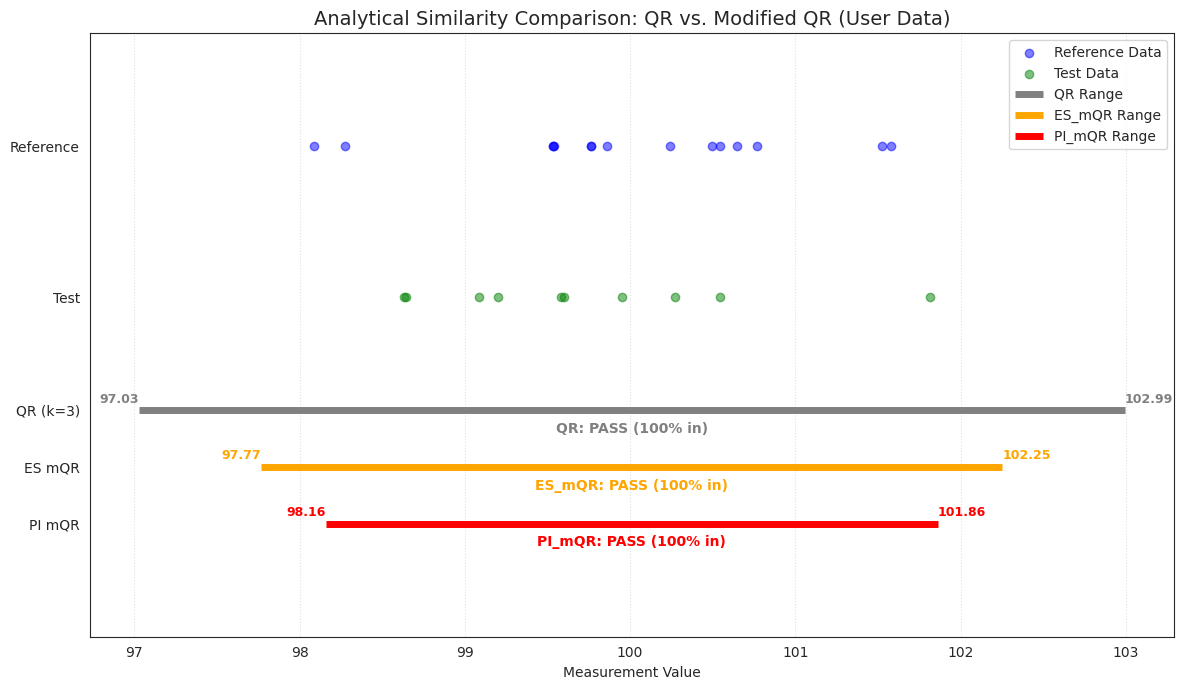

In [ ]:
x_ref_user = np.array([100.49671415, 99.8617357, 100.64768854, 101.52302986, 99.76584663, 99.76586304, 101.57921282, 100.76743473, 99.53052561, 100.54256004, 99.53658231, 99.53427025, 100.24196227, 98.08671976, 98.27508217])
x_test_user = np.array([99.58148372, 99.08588577, 100.54567207, 99.20117352, 98.64646593, 101.81221365, 99.95164607, 100.27428103, 98.632777, 99.601179])

methods = ["QR", "ES_mQR", "PI_mQR"]
results_user = [evaluate_similarity(x_ref_user, x_test_user, method=m) for m in methods]

plt.figure(figsize=(12, 7))
sns.set_style("white")
plt.scatter(x_ref_user, [1.2]*len(x_ref_user), color='blue', alpha=0.5, label='Reference Data', zorder=3)
plt.scatter(x_test_user, [0.8]*len(x_test_user), color='green', alpha=0.5, label='Test Data', zorder=3)

colors = {'QR': 'gray', 'ES_mQR': 'orange', 'PI_mQR': 'red'}
for i, res in enumerate(results_user):
    m_name, lb, ub = res['Method'], res['Lower_Bound'], res['Upper_Bound']
    y_pos = 0.5 - (i * 0.15)
    plt.hlines(y=y_pos, xmin=lb, xmax=ub, color=colors[m_name], lw=5, label=f"{m_name} Range")
    plt.text(lb, y_pos + 0.02, f"{lb:.2f}", color=colors[m_name], fontweight='bold', ha='right', fontsize=9)
    plt.text(ub, y_pos + 0.02, f"{ub:.2f}", color=colors[m_name], fontweight='bold', ha='left', fontsize=9)
    plt.text((lb+ub)/2, y_pos - 0.06, f"{m_name}: {res['Decision']} ({int(res['Inclusion_Proportion']*100)}% in)", color=colors[m_name], ha='center', fontsize=10, fontweight='bold')

plt.yticks([1.2, 0.8, 0.5, 0.35, 0.2], ['Reference', 'Test', 'QR (k=3)', 'ES mQR', 'PI mQR'])
plt.ylim(-0.1, 1.5)
plt.xlabel("Measurement Value")
plt.title("Analytical Similarity Comparison: QR vs. Modified QR (User Data)", fontsize=14)
plt.legend(loc='upper right', frameon=True)
plt.grid(axis='x', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

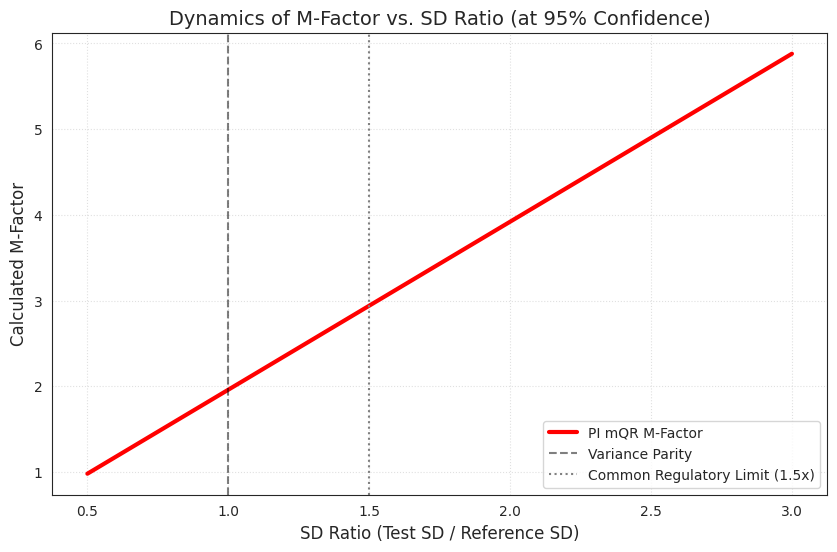

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import root_scalar

def solve_m_factor(r_val, p_target=0.95, d_val=0.0):
    # Objective: find M such that Phi(d + M*r) - Phi(d - M*r) = P_target
    def objective(M):
        return (stats.norm.cdf(d_val + M * r_val) - stats.norm.cdf(d_val - M * r_val)) - p_target

    try:
        res = root_scalar(objective, bracket=[0.001, 20], method='brentq')
        return res.root
    except:
        return np.nan

# Range of SD Ratios (Test SD / Ref SD)
# Note: r_val in the formula is SD_Ref / SD_Test
sd_ratios = np.linspace(0.5, 3.0, 100)
m_factors = [solve_m_factor(1.0/ratio) for ratio in sd_ratios]

plt.figure(figsize=(10, 6))
plt.plot(sd_ratios, m_factors, lw=3, color='red', label='PI mQR M-Factor')
plt.axvline(x=1.0, color='black', linestyle='--', alpha=0.5, label='Variance Parity')
plt.axvline(x=1.5, color='gray', linestyle=':', label='Common Regulatory Limit (1.5x)')

plt.title('Dynamics of M-Factor vs. SD Ratio (at 95% Confidence)', fontsize=14)
plt.xlabel('SD Ratio (Test SD / Reference SD)', fontsize=12)
plt.ylabel('Calculated M-Factor', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.show()

In [ ]:
import numpy as np

# User-provided datasets
x_ref_user = np.array([100.49671415, 99.8617357, 100.64768854, 101.52302986, 99.76584663,
                       99.76586304, 101.57921282, 100.76743473, 99.53052561, 100.54256004,
                       99.53658231, 99.53427025, 100.24196227, 98.08671976, 98.27508217])
x_test_user = np.array([99.58148372, 99.08588577, 100.54567207, 99.20117352, 98.64646593,
                        101.81221365, 99.95164607, 100.27428103, 98.632777, 99.601179])

# Methods to evaluate
methods_to_test = ["QR", "ES_mQR", "PI_mQR"]

print("--- Evaluation Results for User-Provided Data ---")
for m in methods_to_test:
    res = evaluate_similarity(x_ref_user, x_test_user, method=m)
    print(f"\nMethod: {res['Method']}")
    print(f"Decision: {res['Decision']}")
    print(f"Range: [{res['Lower_Bound']:.4f}, {res['Upper_Bound']:.4f}]")
    print(f"Inclusion Proportion: {res['Inclusion_Proportion']:.2%}")

--- Evaluation Results for User-Provided Data ---

Method: QR
Decision: PASS
Range: [97.0279, 102.9928]
Inclusion Proportion: 100.00%

Method: ES_mQR
Decision: PASS
Range: [97.7686, 102.2521]
Inclusion Proportion: 100.00%

Method: PI_mQR
Decision: PASS
Range: [98.1577, 101.8630]
Inclusion Proportion: 100.00%


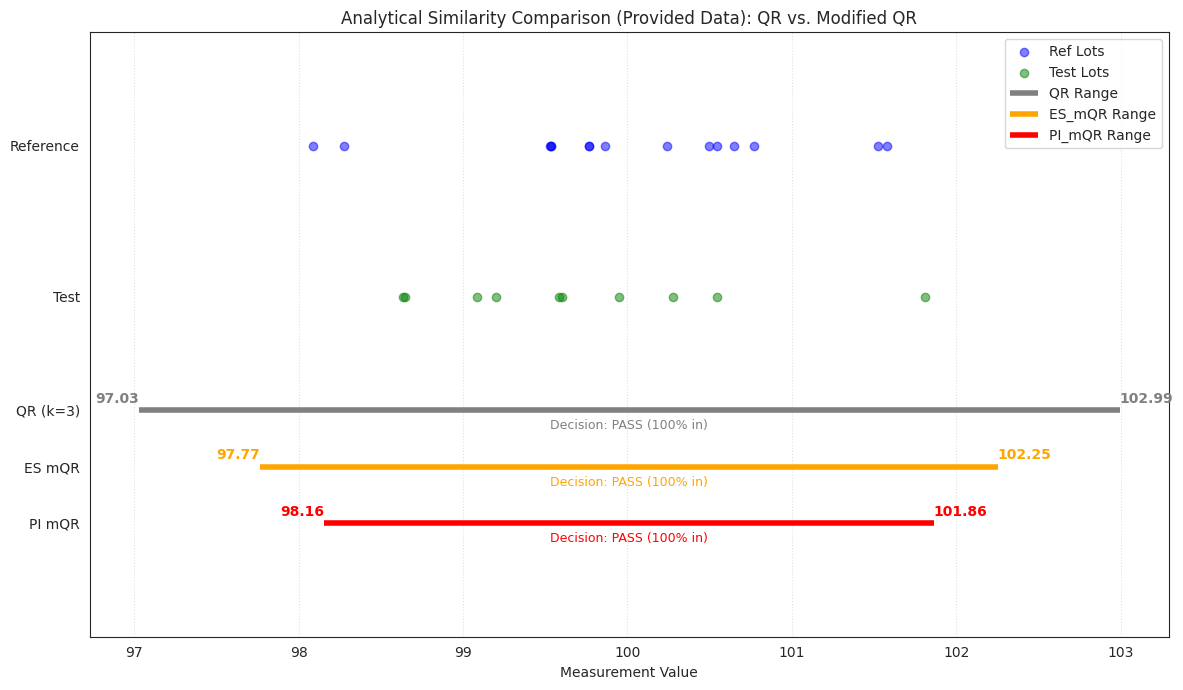

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Data provided by the user
x_ref_user = np.array([100.49671415, 99.8617357, 100.64768854, 101.52302986, 99.76584663,
                       99.76586304, 101.57921282, 100.76743473, 99.53052561, 100.54256004,
                       99.53658231, 99.53427025, 100.24196227, 98.08671976, 98.27508217])

x_test_user = np.array([99.58148372, 99.08588577, 100.54567207, 99.20117352, 98.64646593,
                        101.81221365, 99.95164607, 100.27428103, 98.632777, 99.601179])

# Evaluate methods
methods = ["QR", "ES_mQR", "PI_mQR"]
results_user = [evaluate_similarity(x_ref_user, x_test_user, method=m) for m in methods]

plt.figure(figsize=(12, 7))
sns.set_style("white")

# Plot Data Points
plt.scatter(x_ref_user, [1.2]*len(x_ref_user), color='blue', alpha=0.5, label='Ref Lots', zorder=3)
plt.scatter(x_test_user, [0.8]*len(x_test_user), color='green', alpha=0.5, label='Test Lots', zorder=3)

# Colors for the methods
colors = {'QR': 'gray', 'ES_mQR': 'orange', 'PI_mQR': 'red'}

# Plot the bounds for each method
for i, res in enumerate(results_user):
    m_name = res['Method']
    lb, ub = res['Lower_Bound'], res['Upper_Bound']
    y_pos = 0.5 - (i * 0.15)

    plt.hlines(y=y_pos, xmin=lb, xmax=ub, color=colors[m_name], lw=4, label=f"{m_name} Range")
    plt.text(lb, y_pos + 0.02, f"{lb:.2f}", color=colors[m_name], fontweight='bold', ha='right')
    plt.text(ub, y_pos + 0.02, f"{ub:.2f}", color=colors[m_name], fontweight='bold', ha='left')

    # Indicate Pass/Fail
    plt.text((lb+ub)/2, y_pos - 0.05, f"Decision: {res['Decision']} ({int(res['Inclusion_Proportion']*100)}% in)",
             color=colors[m_name], ha='center', fontsize=9)

plt.yticks([1.2, 0.8, 0.5, 0.35, 0.2], ['Reference', 'Test', 'QR (k=3)', 'ES mQR', 'PI mQR'])
plt.ylim(-0.1, 1.5)
plt.xlabel("Measurement Value")
plt.title("Analytical Similarity Comparison (Provided Data): QR vs. Modified QR")
plt.legend(loc='upper right', frameon=True)
plt.grid(axis='x', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

### Power Analysis: Probability of 'PASS' vs. Sample Size
In this simulation, we assume the **Test Product is identical to the Reference Product** ($N(100, 1)$). We calculate the probability that each method yields a 'PASS' decision (defined as $\ge 90\%$ of lots falling within the calculated range) as the sample size $n_{test}$ increases.

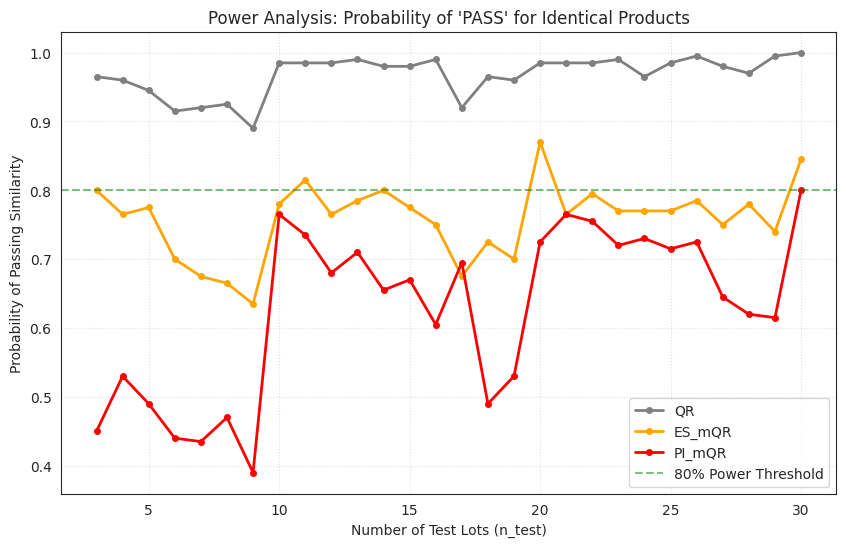

In [ ]:
def run_power_simulation(n_ref=15, n_test_range=range(3, 31), n_sims=200):
    power_results = {m: [] for m in ["QR", "ES_mQR", "PI_mQR"]}

    for n_t in n_test_range:
        temp_pass_counts = {m: 0 for m in power_results.keys()}

        for _ in range(n_sims):
            # Generate identical distributions
            sim_ref = np.random.normal(100, 1, n_ref)
            sim_test = np.random.normal(100, 1, n_t)

            for m in power_results.keys():
                res = evaluate_similarity(sim_ref, sim_test, method=m)
                if res['Decision'] == "PASS":
                    temp_pass_counts[m] += 1

        for m in power_results.keys():
            power_results[m].append(temp_pass_counts[m] / n_sims)

    return n_test_range, power_results

n_range, power_data = run_power_simulation()

plt.figure(figsize=(10, 6))
for m, color in zip(["QR", "ES_mQR", "PI_mQR"], ['gray', 'orange', 'red']):
    plt.plot(n_range, power_data[m], label=m, color=color, marker='o', markersize=4, lw=2)

plt.axhline(y=0.8, color='green', linestyle='--', alpha=0.5, label='80% Power Threshold')
plt.title("Power Analysis: Probability of 'PASS' for Identical Products")
plt.xlabel("Number of Test Lots (n_test)")
plt.ylabel("Probability of Passing Similarity")
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

### Power Curves: Sensitivity to Variance Inflation
This simulation tests the 'anti-gaming' property of the modified methods. We keep the means identical ($100$) and the reference SD fixed at $1.0$, while increasing the test product's SD from $0.5$ to $2.5$. A robust method should show a sharp drop in power as the variance ratio exceeds regulatory expectations (typically $1.5$).

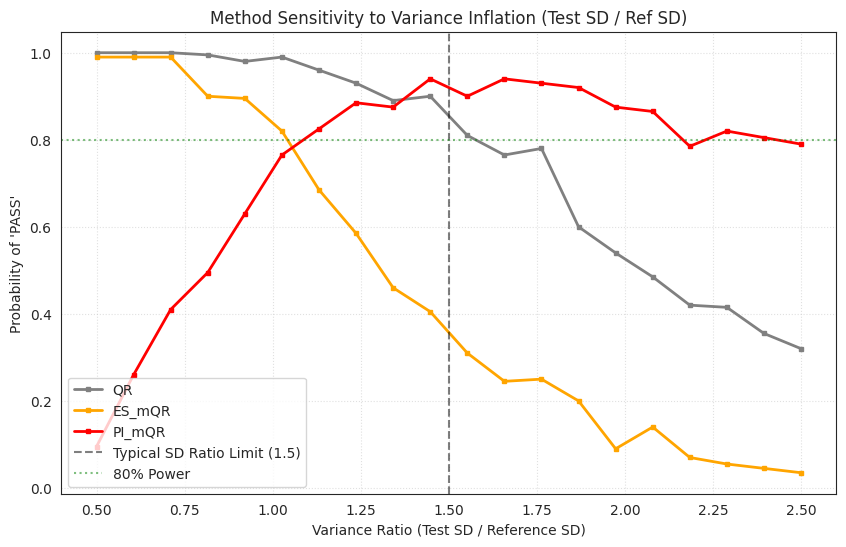

In [ ]:
def run_variance_power_sim(n_ref=15, n_test=10, sd_ratio_range=np.linspace(0.5, 2.5, 20), n_sims=200):
    variance_power = {m: [] for m in ["QR", "ES_mQR", "PI_mQR"]}

    for ratio in sd_ratio_range:
        temp_pass_counts = {m: 0 for m in variance_power.keys()}

        for _ in range(n_sims):
            # Means are identical, but test SD varies
            sim_ref = np.random.normal(100, 1.0, n_ref)
            sim_test = np.random.normal(100, 1.0 * ratio, n_test)

            for m in variance_power.keys():
                res = evaluate_similarity(sim_ref, sim_test, method=m)
                if res['Decision'] == "PASS":
                    temp_pass_counts[m] += 1

        for m in variance_power.keys():
            variance_power[m].append(temp_pass_counts[m] / n_sims)

    return sd_ratio_range, variance_power

ratios, var_power_data = run_variance_power_sim()

plt.figure(figsize=(10, 6))
colors = {'QR': 'gray', 'ES_mQR': 'orange', 'PI_mQR': 'red'}

for m in ["QR", "ES_mQR", "PI_mQR"]:
    plt.plot(ratios, var_power_data[m], label=m, color=colors[m], lw=2, marker='s', markersize=3)

plt.axvline(x=1.5, color='black', linestyle='--', alpha=0.5, label='Typical SD Ratio Limit (1.5)')
plt.axhline(y=0.8, color='green', linestyle=':', alpha=0.5, label='80% Power')

plt.title("Method Sensitivity to Variance Inflation (Test SD / Ref SD)")
plt.xlabel("Variance Ratio (Test SD / Reference SD)")
plt.ylabel("Probability of 'PASS'")
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

### Required Sample Size for 90% Power (PI mQR)
This simulation specifically targets the sample size $n_{test}$ required to achieve 90% power when the test product is identical to the reference. This is critical for ensuring that the stringent PI mQR method doesn't lead to excessive false rejections of truly similar products.

In [ ]:
def find_min_sample_size_expanded(target_power=0.90, n_ref_range=[15, 30, 60], max_n=100, n_sims=400):
    results = {}
    for nr in n_ref_range:
        print(f"Testing n_ref = {nr}...")
        found = False
        for nt in range(10, max_n + 1, 5):
            pass_count = 0
            for _ in range(n_sims):
                sim_ref = np.random.normal(100, 1, nr)
                sim_test = np.random.normal(100, 1, nt)
                res = evaluate_similarity(sim_ref, sim_test, method="PI_mQR")
                if res['Decision'] == "PASS":
                    pass_count += 1

            power = pass_count / n_sims
            if power >= target_power:
                results[nr] = (nt, power)
                print(f"  -> Found: n_test = {nt} gives {power:.2%} power")
                found = True
                break
        if not found:
            results[nr] = (None, None)
    return results

power_results = find_min_sample_size_expanded()

print("\n--- Final Summary (PI mQR at 90% Power) ---")
for nr, (nt, p) in power_results.items():
    if nt:
        print(f"For n_ref={nr}: Min n_test required = {nt}")
    else:
        print(f"For n_ref={nr}: Could not reach 90% power within n_test=100")

Testing n_ref = 15...
Testing n_ref = 30...
Testing n_ref = 60...
  -> Found: n_test = 50 gives 90.00% power

--- Final Summary (PI mQR at 90% Power) ---
For n_ref=15: Could not reach 90% power within n_test=100
For n_ref=30: Could not reach 90% power within n_test=100
For n_ref=60: Min n_test required = 50


In [ ]:
def find_min_n_test_standard_method(target_power=0.90, n_ref_range=[15, 30, 60], max_n=100, beta=0.99, gamma=0.95, n_sims=500):
    results = {}
    for nr in n_ref_range:
        print(f"Analyzing standard TI-PI nesting for n_ref = {nr}...")
        found = False
        for nt in range(2, max_n + 1):
            successes = 0
            for _ in range(n_sims):
                sim_ref = np.random.normal(100, 1, nr)
                sim_test = np.random.normal(100, 1, nt)

                ti_l, ti_u = calc_ref_TI(sim_ref, beta, gamma)
                pi_l, pi_u = calc_test_PI(sim_test, beta)

                if (pi_l >= ti_l) and (pi_u <= ti_u):
                    successes += 1

            power = successes / n_sims
            if power >= target_power:
                results[nr] = (nt, power)
                print(f"  -> Success: n_test = {nt} reached {power:.1%} power")
                found = True
                break
        if not found:
            results[nr] = (None, None)
    return results

# Run simulation
standard_power_results = find_min_n_test_standard_method()

print("\n--- Required n_test for 90% Power (Standard TI/PI Nesting) ---")
for nr, (nt, p) in standard_power_results.items():
    if nt:
        print(f"For n_ref={nr}: Min n_test required = {nt} (at {p:.2%} power)")
    else:
        print(f"For n_ref={nr}: Target power not reached within n_test=100")

Analyzing standard TI-PI nesting for n_ref = 15...
  -> Success: n_test = 50 reached 90.0% power
Analyzing standard TI-PI nesting for n_ref = 30...
Analyzing standard TI-PI nesting for n_ref = 60...

--- Required n_test for 90% Power (Standard TI/PI Nesting) ---
For n_ref=15: Min n_test required = 50 (at 90.00% power)
For n_ref=30: Target power not reached within n_test=100
For n_ref=60: Target power not reached within n_test=100


<>:69: SyntaxWarning: invalid escape sequence '\c'
<>:72: SyntaxWarning: invalid escape sequence '\s'
<>:69: SyntaxWarning: invalid escape sequence '\c'
<>:72: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_6757/2616698289.py:69: SyntaxWarning: invalid escape sequence '\c'
  ax1.axhline(y=stats.norm.ppf(0.995)*sigma_R, color='gray', linestyle=':', label=f'Asymptotic Limit ($z_{{0.995}} \cdot \sigma_R$)')
/tmp/ipykernel_6757/2616698289.py:72: SyntaxWarning: invalid escape sequence '\s'
  ax1.set_ylabel('TI Half-Width ($\sigma_R$ units)', fontsize=11)


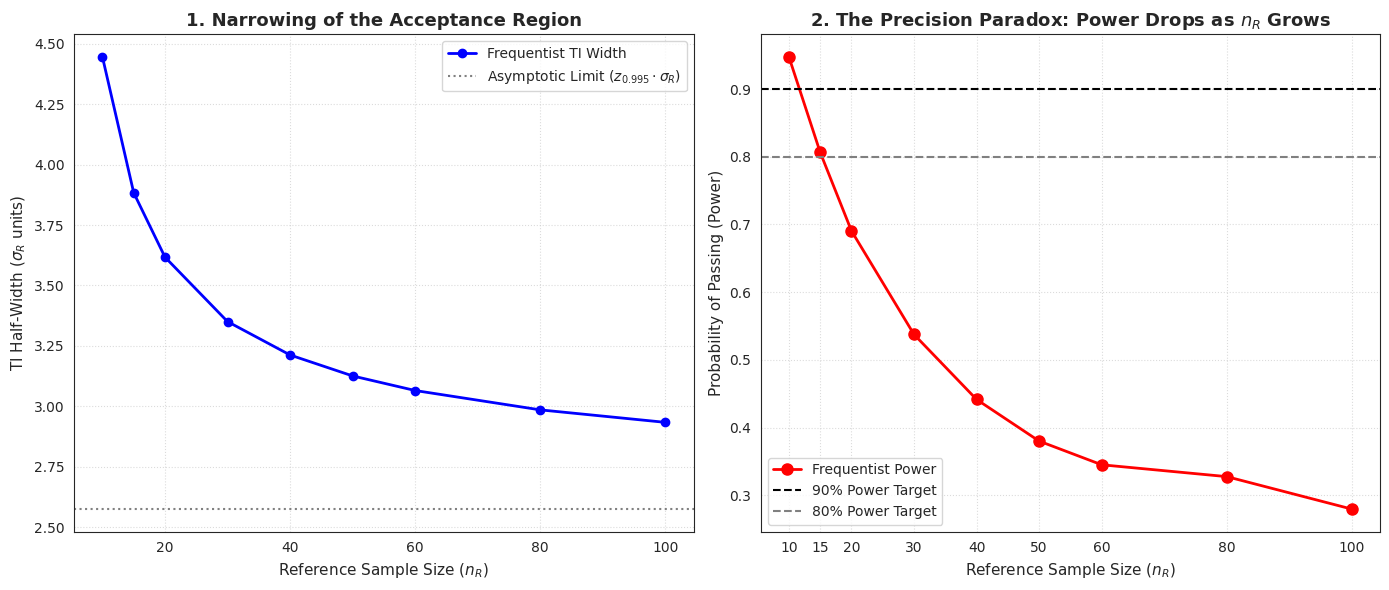

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# ==========================================
# 1. Define Interval Calculation Functions
# ==========================================
def calc_ti_half_width(n, sigma=1.0, beta=0.99, gamma=0.95):
    """Calculates the expected half-width of a beta-gamma Tolerance Interval."""
    z_val = stats.norm.ppf((1 + beta) / 2)
    chi2_val = stats.chi2.ppf(1 - gamma, df=n - 1)
    k_c = z_val * np.sqrt((n - 1) / chi2_val) * np.sqrt(1 + 1 / n)
    return k_c * sigma

def calc_pi_half_width(x_test, beta=0.99):
    """Calculates the half-width of a beta Prediction Interval."""
    n = len(x_test)
    sd = np.std(x_test, ddof=1)
    t_crit = stats.t.ppf((1 + beta) / 2, df=n - 1)
    return t_crit * sd * np.sqrt(1 + 1 / n)

# ==========================================
# 2. Simulation Parameters
# ==========================================
n_T = 15               # Fixed test sample size
n_R_values = [10, 15, 20, 30, 40, 50, 60, 80, 100]
n_sims = 2000          # Monte Carlo iterations
beta, gamma = 0.99, 0.95

# True State: Test product has a minor, clinically irrelevant mean shift
mu_R, sigma_R = 100.0, 1.0
mu_T, sigma_T = 100.2, 1.0  # Shift of 0.2 sigma

powers = []
np.random.seed(42)

# ==========================================
# 3. Monte Carlo Simulation for Power
# ==========================================
for n_R in n_R_values:
    passes = 0
    for _ in range(n_sims):
        # Generate Reference Data & Calculate TI
        x_ref = np.random.normal(mu_R, sigma_R, n_R)
        ref_mean = np.mean(x_ref)
        ref_hw = calc_ti_half_width(n_R, sigma_R, beta, gamma) # Using expected width for stability
        ref_lower, ref_upper = ref_mean - ref_hw, ref_mean + ref_hw

        # Generate Test Data & Calculate PI
        x_test = np.random.normal(mu_T, sigma_T, n_T)
        test_mean = np.mean(x_test)
        test_hw = calc_pi_half_width(x_test, beta)
        test_lower, test_upper = test_mean - test_hw, test_mean + test_hw

        # Check Strict Nesting
        if test_lower >= ref_lower and test_upper <= ref_upper:
            passes += 1

    powers.append(passes / n_sims)

# ==========================================
# 4. Visualization of the Precision Paradox
# ==========================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Plot 1: Narrowing of the Acceptance Region
ti_widths = [calc_ti_half_width(n, sigma_R, beta, gamma) for n in n_R_values]
ax1.plot(n_R_values, ti_widths, marker='o', linestyle='-', color='blue', linewidth=2, label='Frequentist TI Width')
ax1.axhline(y=stats.norm.ppf(0.995)*sigma_R, color='gray', linestyle=':', label=f'Asymptotic Limit ($z_{{0.995}} \cdot \sigma_R$)')
ax1.set_title('1. Narrowing of the Acceptance Region', fontsize=13, fontweight='bold')
ax1.set_xlabel('Reference Sample Size ($n_R$)', fontsize=11)
ax1.set_ylabel('TI Half-Width ($\sigma_R$ units)', fontsize=11)
ax1.legend()
ax1.grid(True, linestyle=':', alpha=0.7)

# Plot 2: The Precision Paradox (Power Drop)
ax2.plot(n_R_values, powers, marker='o', linestyle='-', color='red', linewidth=2, markersize=8, label='Frequentist Power')
ax2.axhline(y=0.90, color='black', linestyle='--', linewidth=1.5, label='90% Power Target')
ax2.axhline(y=0.80, color='gray', linestyle='--', linewidth=1.5, label='80% Power Target')
ax2.set_title('2. The Precision Paradox: Power Drops as $n_R$ Grows', fontsize=13, fontweight='bold')
ax2.set_xlabel('Reference Sample Size ($n_R$)', fontsize=11)
ax2.set_ylabel('Probability of Passing (Power)', fontsize=11)
ax2.set_xticks(n_R_values)
ax2.legend()
ax2.grid(True, linestyle=':', alpha=0.7)

plt.tight_layout()
plt.show()

### Head-to-Head: Bayesian Informative vs. PI mQR
This simulation compares the power (probability of passing) for both methods. We use a prior strength of $\kappa_0=10$ (equivalent to 10 historical samples) for the Bayesian model.

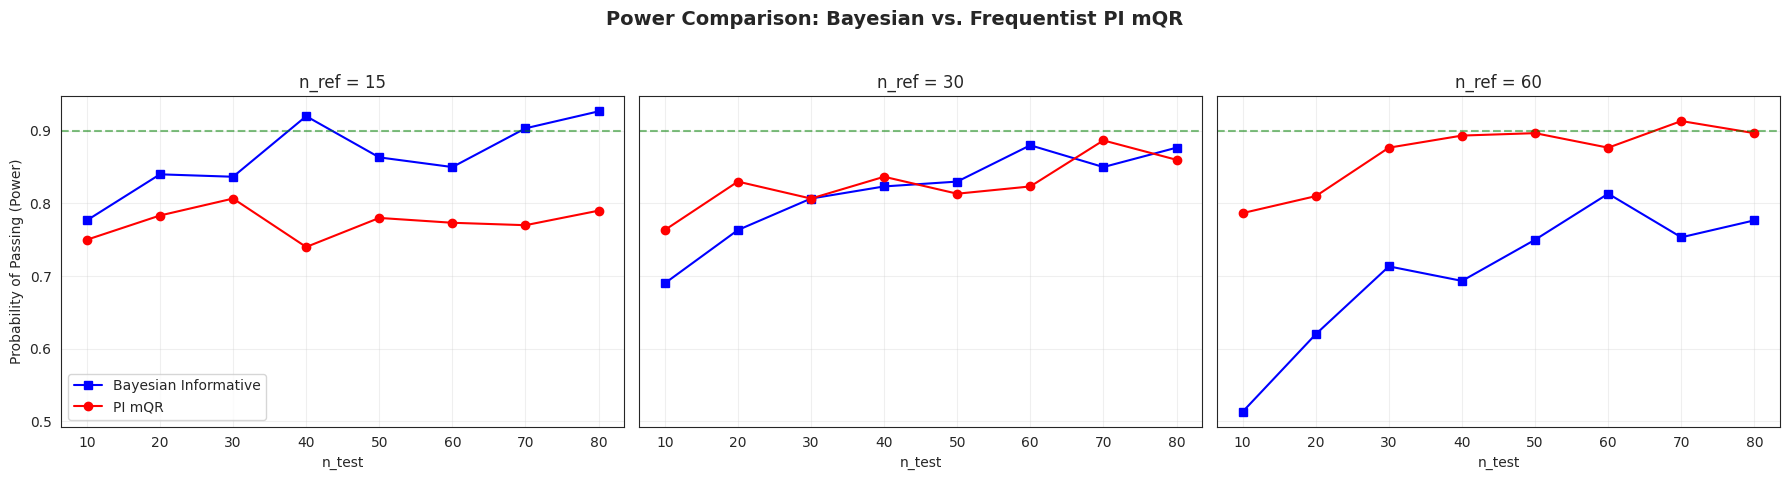

In [ ]:
n_ref_list = [15, 30, 60]
n_test_range = range(10, 81, 10)
prior_k10 = {'mu0': 100, 'kappa0': 10, 'alpha0': 5, 'beta0': 5}
n_sims = 300

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

for idx, nr in enumerate(n_ref_list):
    p_bayes = []
    p_pi_mqr = []

    for nt in n_test_range:
        passes_b = 0
        passes_p = 0
        for _ in range(n_sims):
            s_ref = np.random.normal(100, 1, nr)
            s_test = np.random.normal(100, 1, nt)

            # Bayesian Informative
            ref_l, ref_u = calc_ref_TI(s_ref, 0.99, 0.95)
            b_l, b_u = calc_informative_bayesian_pi(s_test, prior_k10, 0.99)
            if b_l >= ref_l and b_u <= ref_u:
                passes_b += 1

            # PI mQR
            res = evaluate_similarity(s_ref, s_test, method='PI_mQR')
            if res['Decision'] == 'PASS':
                passes_p += 1

        p_bayes.append(passes_b / n_sims)
        p_pi_mqr.append(passes_p / n_sims)

    axes[idx].plot(n_test_range, p_bayes, 'b-s', label='Bayesian Informative')
    axes[idx].plot(n_test_range, p_pi_mqr, 'r-o', label='PI mQR')
    axes[idx].axhline(0.9, color='green', linestyle='--', alpha=0.5)
    axes[idx].set_title(f'n_ref = {nr}')
    axes[idx].set_xlabel('n_test')
    axes[idx].grid(True, alpha=0.3)

axes[0].set_ylabel('Probability of Passing (Power)')
axes[0].legend()
plt.suptitle('Power Comparison: Bayesian vs. Frequentist PI mQR', fontsize=14, fontweight='bold')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

### Understanding Prior Strength ($\kappa_0$)
The following visualization shows the 'Bayesian Tug-of-War'. As $\kappa_0$ increases, the result stays closer to the Historical Prior Mean (100) and resists being pulled away by the Observed Sample Mean (105).

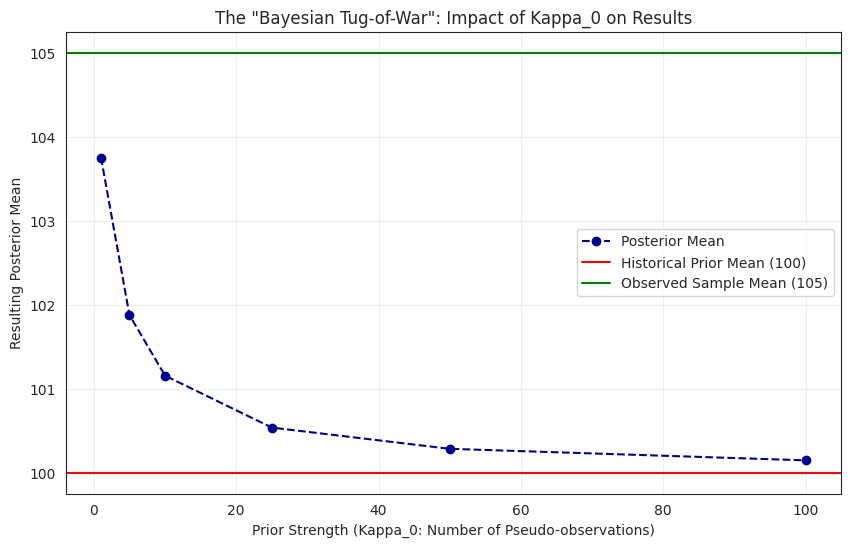

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Scenario: Historical Mean is 100, but the new small sample (n=3) mean is 105
hist_mu = 100.0
new_sample = np.array([104.5, 105.0, 105.5])
n_test = len(new_sample)
x_bar = np.mean(new_sample)

kappa_range = [1, 5, 10, 25, 50, 100]
post_means = []

for k0 in kappa_range:
    # Posterior Mean formula: weighted average of prior and data
    mu_n = (k0 * hist_mu + n_test * x_bar) / (k0 + n_test)
    post_means.append(mu_n)

plt.figure(figsize=(10, 6))
plt.plot(kappa_range, post_means, marker='o', linestyle='--', color='darkblue', label='Posterior Mean')
plt.axhline(y=hist_mu, color='red', label='Historical Prior Mean (100)')
plt.axhline(y=x_bar, color='green', label='Observed Sample Mean (105)')

plt.title('The "Bayesian Tug-of-War": Impact of Kappa_0 on Results')
plt.xlabel('Prior Strength (Kappa_0: Number of Pseudo-observations)')
plt.ylabel('Resulting Posterior Mean')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

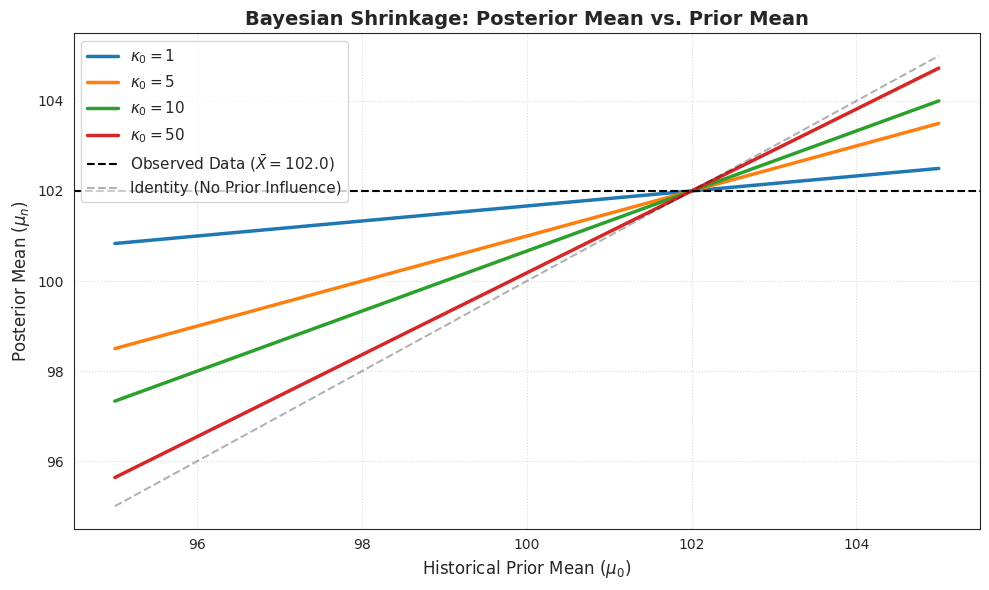

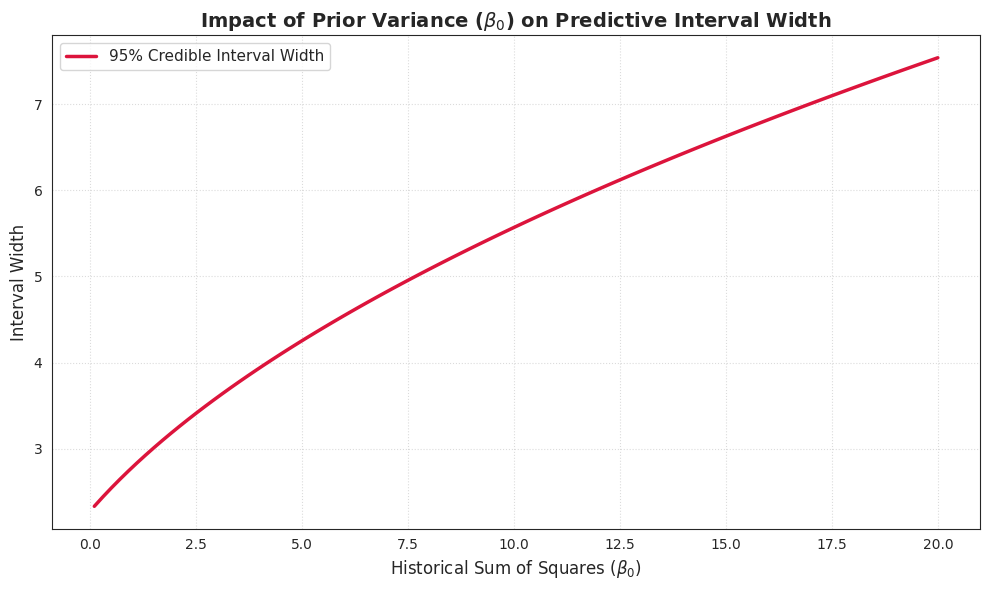

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

def plot_shrinkage_effect():
    """
    Visualizes the 'Tug-of-War' (Shrinkage Effect) of the Prior Strength (kappa_0).
    Demonstrates how the posterior mean is pulled toward the prior mean.
    """
    n = 5
    x_bar = 102.0  # Observed test mean
    mu_0_values = np.linspace(95, 105, 100)
    kappas = [1, 5, 10, 50]

    plt.figure(figsize=(10, 6))
    for k in kappas:
        # Posterior mean equation: mu_n = (kappa_0 * mu_0 + n * X_bar) / (kappa_0 + n)
        mu_n = (k * mu_0_values + n * x_bar) / (k + n)
        plt.plot(mu_0_values, mu_n, label=r'$\kappa_0 = {}$'.format(k), linewidth=2.5)

    plt.axhline(y=x_bar, color='black', linestyle='--', linewidth=1.5,
                label=r'Observed Data ($\bar{{X}} = {}$)'.format(x_bar)) # Fixed: Doubled braces for LaTeX
    plt.plot([95, 105], [95, 105], 'k--', alpha=0.3, linewidth=1.5,
             label='Identity (No Prior Influence)')

    plt.title('Bayesian Shrinkage: Posterior Mean vs. Prior Mean', fontsize=14, fontweight='bold')
    plt.xlabel(r'Historical Prior Mean ($\mu_0$)', fontsize=12)
    plt.ylabel(r'Posterior Mean ($\mu_n$)', fontsize=12)
    plt.legend(fontsize=11, loc='upper left')
    plt.grid(True, linestyle=':', alpha=0.7)
    plt.tight_layout()
    plt.show()

def plot_variance_confidence():
    """
    Visualizes the impact of Prior Variance (beta_0) on the Predictive Interval Width.
    Demonstrates how historical volatility scales the Bayesian Credible Interval.
    """
    n = 5
    s_sq = 1.0       # Observed sample variance
    x_bar = 100.0
    mu_0 = 100.0
    alpha_0 = 5.0    # Equivalent to 10 historical lots (alpha_0 = n_hist / 2)
    kappa_0 = 10.0

    beta_0_values = np.linspace(0.1, 20, 100)
    interval_widths = []

    for b0 in beta_0_values:
        # Bayesian posterior updates
        alpha_n = alpha_0 + n / 2
        beta_n = b0 + (n - 1) * s_sq / 2 + (kappa_0 * n) / (2 * (kappa_0 + n)) * (x_bar - mu_0)**2

        # Scale squared for the posterior predictive t-distribution
        scale_sq = (beta_n / alpha_n) * (1 + 1 / (kappa_0 + n))
        df = 2 * alpha_n

        # Calculate 95% Credible Interval width
        t_crit = stats.t.ppf(0.975, df)
        width = 2 * t_crit * np.sqrt(scale_sq)
        interval_widths.append(width)

    plt.figure(figsize=(10, 6))
    plt.plot(beta_0_values, interval_widths, color='crimson', linewidth=2.5,
             label='95% Credible Interval Width')
    plt.title(r'Impact of Prior Variance ($\beta_0$) on Predictive Interval Width',
              fontsize=14, fontweight='bold')
    plt.xlabel(r'Historical Sum of Squares ($\beta_0$)', fontsize=12)
    plt.ylabel('Interval Width', fontsize=12)
    plt.grid(True, linestyle=':', alpha=0.7)
    plt.legend(fontsize=11)
    plt.tight_layout()
    plt.show()

# Execute the visualizations
plot_shrinkage_effect()
plot_variance_confidence()

### Impact of Prior Shape ($\alpha_0$) on Interval Width
This simulation keeps $\kappa_0$ and $\beta_0$ fixed to isolate how the 'degrees of freedom' we assign to our historical variance ($\alpha_0$) affects the final credible interval.

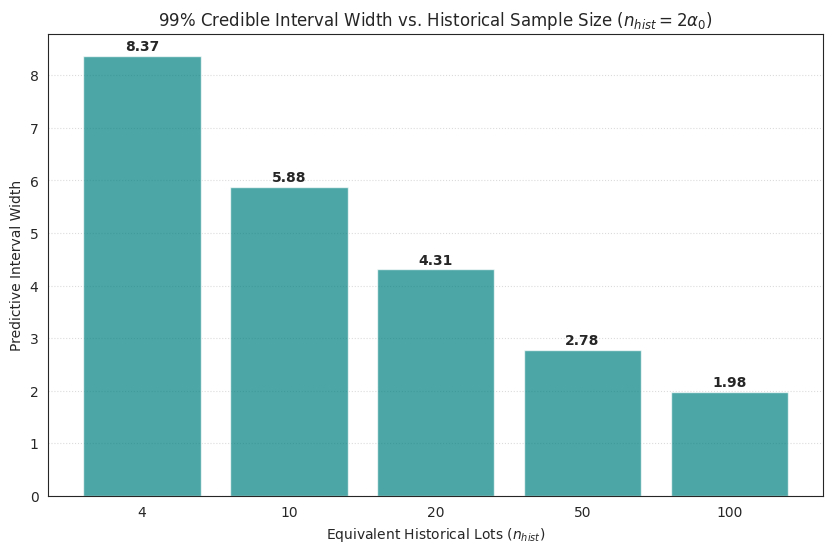

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Fixed parameters
n = 5
s_sq = 1.0
x_bar = 100.0
mu_0 = 100.0
kappa_0 = 10.0
beta_0 = 5.0 # Fixed scale

alpha_values = [2, 5, 10, 25, 50] # Equivalent to 4, 10, 20, 50, 100 historical lots
widths = []

for a0 in alpha_values:
    # Posterior Update
    alpha_n = a0 + n/2
    beta_n = beta_0 + (n-1)*s_sq/2 + (kappa_0*n)/(2*(kappa_0+n)) * (x_bar - mu_0)**2

    # Predictive t-distribution scale
    scale = np.sqrt((beta_n * (kappa_0 + n + 1)) / (alpha_n * (kappa_0 + n)))
    df = 2 * alpha_n

    # Width of 99% interval
    l, u = stats.t.interval(0.99, df=df, loc=x_bar, scale=scale)
    widths.append(u - l)

plt.figure(figsize=(10, 6))
plt.bar([str(a*2) for a in alpha_values], widths, color='teal', alpha=0.7)
# Use a raw string (r'') to prevent backslash escaping
plt.title(r'99% Credible Interval Width vs. Historical Sample Size ($n_{hist} = 2\alpha_0$)')
plt.xlabel('Equivalent Historical Lots ($n_{hist}$)')
plt.ylabel('Predictive Interval Width')
plt.grid(axis='y', linestyle=':', alpha=0.7)

for i, v in enumerate(widths):
    plt.text(i, v + 0.1, f"{v:.2f}", ha='center', fontweight='bold')

plt.show()

n_ref= 15, n_test= 10: PI mQR power=0.882 +/- 0.014, Bayes NIG power=0.398 +/- 0.022
n_ref= 15, n_test= 20: PI mQR power=0.922 +/- 0.012, Bayes NIG power=0.554 +/- 0.022
n_ref= 15, n_test= 30: PI mQR power=0.946 +/- 0.010, Bayes NIG power=0.598 +/- 0.022
n_ref= 15, n_test= 40: PI mQR power=0.942 +/- 0.010, Bayes NIG power=0.622 +/- 0.022
n_ref= 15, n_test= 50: PI mQR power=0.942 +/- 0.010, Bayes NIG power=0.664 +/- 0.021
n_ref= 15, n_test= 60: PI mQR power=0.944 +/- 0.010, Bayes NIG power=0.728 +/- 0.020
n_ref= 15, n_test= 70: PI mQR power=0.962 +/- 0.009, Bayes NIG power=0.694 +/- 0.021
n_ref= 15, n_test= 80: PI mQR power=0.964 +/- 0.008, Bayes NIG power=0.712 +/- 0.020
n_ref= 15, n_test= 90: PI mQR power=0.976 +/- 0.007, Bayes NIG power=0.752 +/- 0.019
n_ref= 15, n_test=100: PI mQR power=0.954 +/- 0.009, Bayes NIG power=0.738 +/- 0.020
n_ref= 30, n_test= 10: PI mQR power=0.892 +/- 0.014, Bayes NIG power=0.496 +/- 0.022
n_ref= 30, n_test= 20: PI mQR power=0.954 +/- 0.009, Bayes NIG po

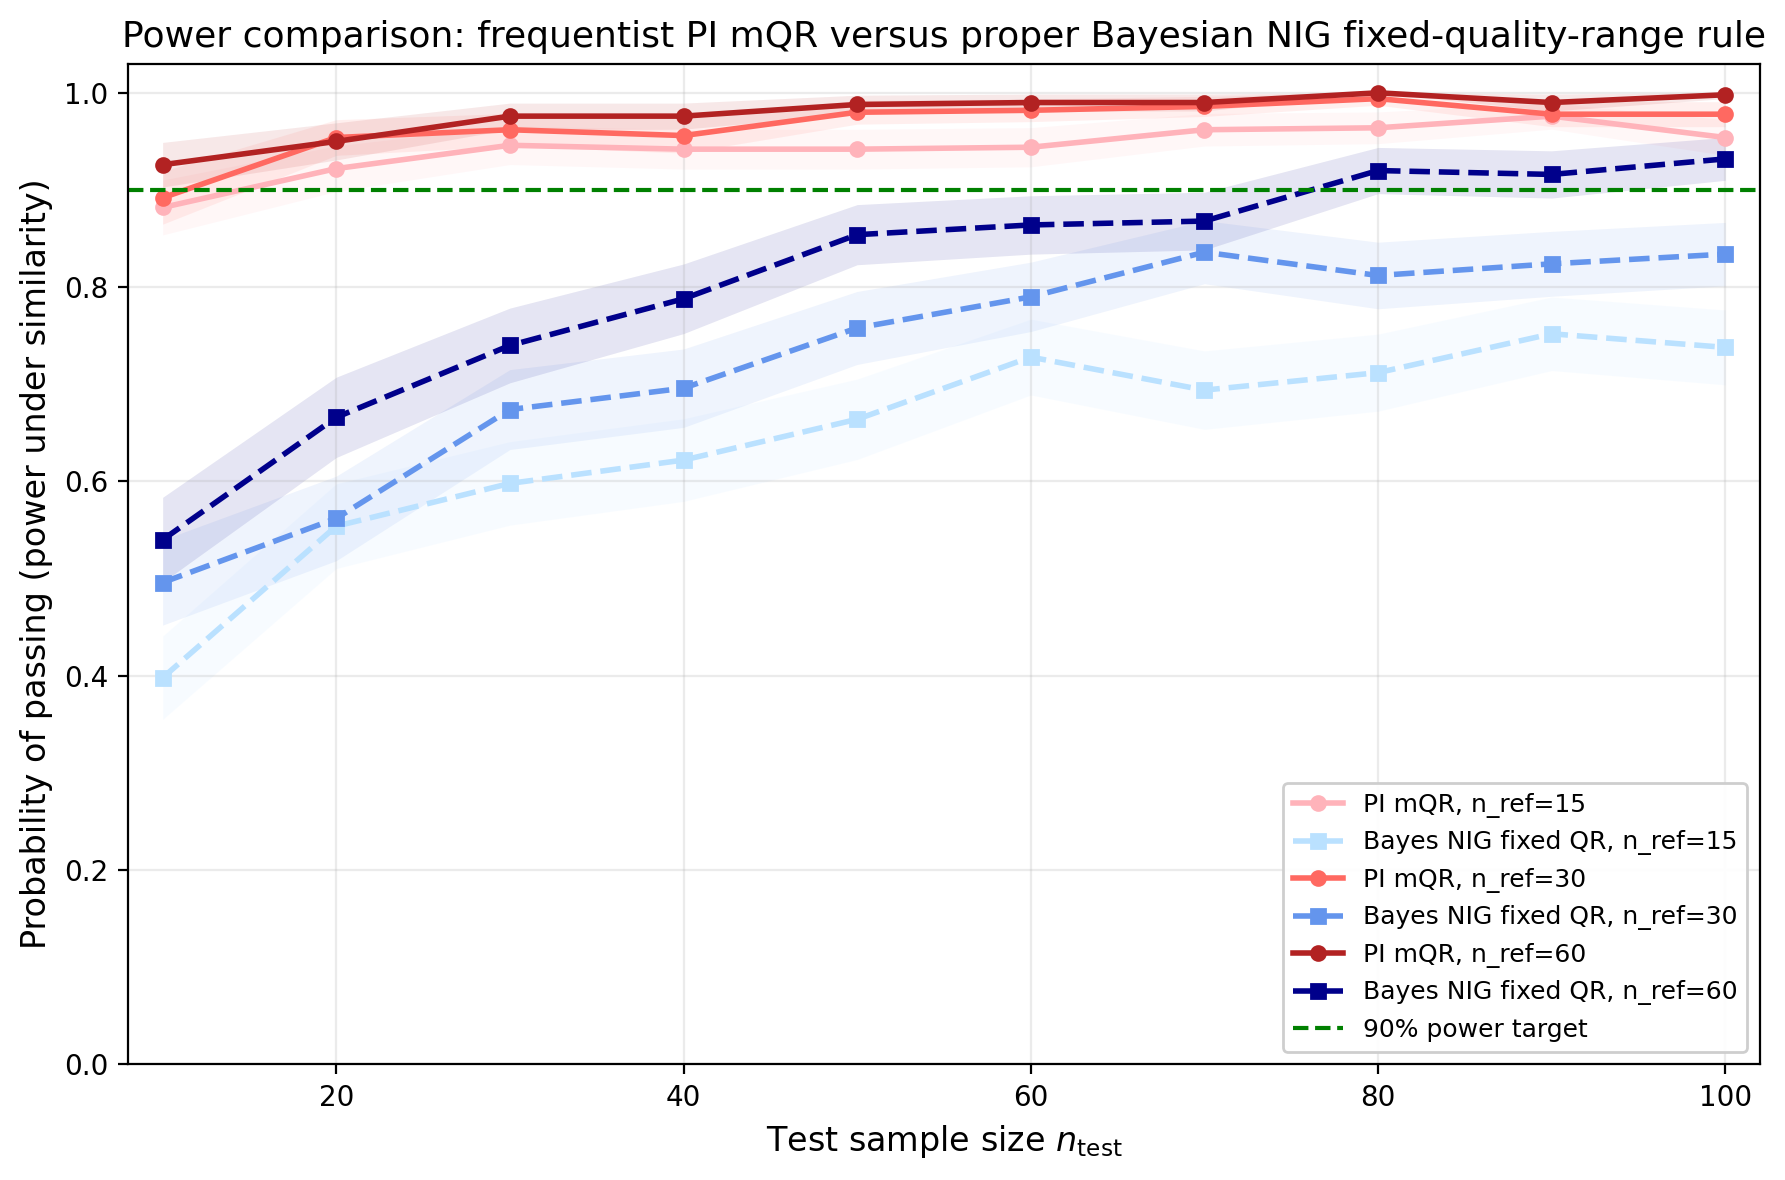

Figure saved to: Bayesian_vs_frequentist.png


In [1]:
"""
Figure: Bayesian_vs_frequentist.png

Comparison of:
  1. Frequentist PI mQR / PI mQA-style modified quality range method.
  2. Bayesian Normal-Inverse-Gamma method.

Default Bayesian rule:
  Proper fixed-quality-range NIG posterior containment rule.
  This rule does NOT use a shrinking reference credible interval as
  the acceptance region and therefore avoids the precision paradox.

Optional diagnostic rule:
  Naive strict nesting of Bayesian posterior predictive intervals.
  This can reproduce the apparent precision paradox and should be
  interpreted only as a diagnostic of a bad decision rule, not as
  an intrinsic property of the NIG prior.

Interpretation note:
  The code assumes PI mQA means PI mQR. If PI mQA is a different
  algorithm, replace pi_mqr_pass() with the exact defining rule.
"""

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, t
from scipy.optimize import brentq


# ----------------------------------------------------------------------------
# 1. Global simulation and decision parameters
# ----------------------------------------------------------------------------

SEED = 20261021

# Number of Monte Carlo replications for each (n_ref, n_test) point.
# Increase for smoother curves; decrease for faster exploration.
N_SIM = 500

# Number of posterior draws for the Bayesian NIG calculation.
# Increase for more stable Bayesian decisions; decrease for speed.
B_POST = 1000

# Reference sample sizes to compare.
N_REF_VALUES = [15, 30, 60]

# Test sample sizes for the power curve.
N_TEST_VALUES = np.arange(10, 101, 10)

# True generating distribution under the similarity / alternative scenario.
# Here the test product is truly similar to the reference product.
TRUE_MU_R = 0.0
TRUE_SIGMA_R = 1.0

TRUE_MU_T = 0.0
TRUE_SIGMA_T = 1.0

# -------------------------------------------------------------------------
# Frequentist PI mQR parameters
# -------------------------------------------------------------------------
# p_interval is the nominal probability mass used to construct the modified
# quality range through the plausibility integral.
#
# p_pass is the empirical fraction of test lots that must fall inside the
# constructed range for a pass decision.
#
# To avoid placing the true similarity scenario exactly on the decision
# boundary, p_interval is set slightly above p_pass. This is analogous to
# using a quality range with, for example, 97.5% nominal reference content
# while requiring 90% of test lots to fall inside it.
P_INTERVAL = 0.975
P_PASS = 0.90

# -------------------------------------------------------------------------
# Bayesian NIG parameters
# -------------------------------------------------------------------------
# BAYESIAN_MODE:
#   "proper" : fixed-quality-range posterior containment rule.
#              Recommended. Avoids the precision paradox.
#
#   "naive"  : strict nesting of posterior predictive intervals.
#              Diagnostic only. Can reproduce the apparent precision paradox.
BAYESIAN_MODE = "proper"

# Posterior probability threshold for the proper Bayesian rule.
# Declare similarity if
#   Pr{ psi(theta_T, theta_R; K) >= P_PASS | data } >= C_BAYES.
C_BAYES = 0.95

# NIG prior parameters.
#
# The prior is written as
#   mu | sigma^2 ~ Normal(mu0, sigma^2 / kappa0)
#   sigma^2      ~ Inv-Gamma(alpha0, beta0)
#
# using the shape-scale Inv-Gamma parameterization:
#   p(sigma^2) proportional to (sigma^2)^(-alpha0 - 1) exp(-beta0 / sigma^2).
#
# The prior mean of sigma^2 is beta0 / (alpha0 - 1), when alpha0 > 1.
#
# These defaults encode moderately informative historical process knowledge
# centered at the true reference mean and variance. For a conservative SAP,
# reduce kappa0, alpha0, beta0, or perform sensitivity analysis over them.
PRIOR = {
    "mu0": 0.0,
    "kappa0": 20.0,
    "alpha0": 10.0,
    "beta0": 10.0,
}

# For the naive strict-nesting diagnostic, a weaker prior makes the
# finite-sample posterior predictive inflation more visible.
NAIVE_PRIOR = {
    "mu0": 0.0,
    "kappa0": 1.0,
    "alpha0": 1.0,
    "beta0": 1.0,
}

# The naive nesting diagnostic is usually run at the bare containment target,
# e.g. 90%, which is where the pathological contraction behavior is most acute.
NAIVE_P_INTERVAL = 0.90


# ----------------------------------------------------------------------------
# 2. Normal-Inverse-Gamma posterior machinery
# ----------------------------------------------------------------------------

def nig_posterior_parameters(
    x: np.ndarray,
    mu0: float,
    kappa0: float,
    alpha0: float,
    beta0: float,
):
    """
    Posterior parameters for the conjugate Normal-Inverse-Gamma model.

    Model:
        x_i | mu, sigma^2 ~ Normal(mu, sigma^2)

        mu | sigma^2 ~ Normal(mu0, sigma^2 / kappa0)
        sigma^2      ~ Inv-Gamma(alpha0, beta0)

    Returns:
        kappa_n, mu_n, alpha_n, beta_n
    """
    n = len(x)
    if n == 0:
        raise ValueError("Cannot update NIG posterior with zero observations.")

    xbar = float(np.mean(x))

    if n > 1:
        s2 = float(np.var(x, ddof=1))
    else:
        s2 = 0.0

    kappa_n = kappa0 + n
    mu_n = (kappa0 * mu0 + n * xbar) / kappa_n
    alpha_n = alpha0 + n / 2.0

    beta_n = (
        beta0
        + 0.5 * (n - 1) * s2
        + 0.5 * kappa0 * n / (kappa0 + n) * (xbar - mu0) ** 2
    )

    return kappa_n, mu_n, alpha_n, beta_n


def sample_inverse_gamma(
    rng: np.random.Generator,
    alpha: float,
    beta: float,
    size: int,
) -> np.ndarray:
    """
    Sample from Inv-Gamma(alpha, beta) using the shape-scale parameterization:

        p(x) proportional to x^(-alpha - 1) exp(-beta / x),  x > 0.

    This is achieved by sampling Y ~ Gamma(shape=alpha, rate=beta)
    and returning X = 1 / Y.

    NumPy's Generator.gamma uses scale, not rate, so scale = 1 / beta.
    """
    if alpha <= 0:
        raise ValueError("Inv-Gamma shape alpha must be positive.")
    if beta <= 0:
        raise ValueError("Inv-Gamma scale beta must be positive.")

    y = rng.gamma(shape=alpha, scale=1.0 / beta, size=size)
    return 1.0 / y


# ----------------------------------------------------------------------------
# 3. Frequentist PI mQR / PI mQA-style rule
# ----------------------------------------------------------------------------

def pi_mqr_pass(
    ref: np.ndarray,
    test: np.ndarray,
    p_interval: float = P_INTERVAL,
    p_pass: float = P_PASS,
) -> bool:
    """
    Frequentist PI mQR-style modified quality range decision rule.

    Construction:
        Let
            d = (mu_R_hat - mu_T_hat) / sigma_T_hat
            r = sigma_R_hat / sigma_T_hat.

        Solve for M such that
            Phi(d + M r) - Phi(d - M r) = p_interval.

        Apply the variance-asymmetry scale
            q = min(sigma_R_hat, sigma_T_hat).

        Construct the modified range
            [mu_R_hat - M q, mu_R_hat + M q].

    Decision:
        Pass if at least p_pass fraction of observed test lots fall inside
        the modified range.
    """
    n_T = len(test)
    if n_T == 0:
        return False

    mu_R = float(np.mean(ref))
    sigma_R = float(np.std(ref, ddof=1))

    mu_T = float(np.mean(test))
    sigma_T = float(np.std(test, ddof=1))

    if sigma_R <= 0.0 or sigma_T <= 0.0:
        return False

    d = (mu_R - mu_T) / sigma_T
    r = sigma_R / sigma_T

    def plausibility_equation(M: float) -> float:
        return (
            norm.cdf(d + M * r)
            - norm.cdf(d - M * r)
            - p_interval
        )

    # The function is monotone increasing in M.
    # Find a bracketing upper bound.
    high = 10.0
    for _ in range(14):
        if plausibility_equation(high) >= 0.0:
            break
        high *= 2.0
    else:
        # Fallback for extreme numerical cases.
        M = norm.ppf((1.0 + p_interval) / 2.0) / max(r, 1e-12)
        scale = sigma_T if sigma_R > sigma_T else sigma_R
        lower = mu_R - M * scale
        upper = mu_R + M * scale
        count = np.sum((test >= lower) & (test <= upper))
        required = int(np.ceil(p_pass * n_T))
        return bool(count >= required)

    try:
        M = brentq(
            plausibility_equation,
            0.0,
            high,
            xtol=1e-12,
            rtol=1e-12,
            maxiter=200,
        )
    except ValueError:
        # Conservative fallback if root finding fails.
        M = norm.ppf((1.0 + p_interval) / 2.0) / max(r, 1e-12)

    # Variance-asymmetry scale:
    # If the test product is more variable, scale by reference SD.
    # If the test product appears less variable, scale by test SD to avoid
    # an oversized reference-based range masking a mean shift.
    scale = sigma_T if sigma_R > sigma_T else sigma_R

    lower = mu_R - M * scale
    upper = mu_R + M * scale

    count_inside = np.sum((test >= lower) & (test <= upper))
    required_count = int(np.ceil(p_pass * n_T))

    return bool(count_inside >= required_count)


# ----------------------------------------------------------------------------
# 4. Proper Bayesian NIG rule: fixed quality range, posterior containment
# ----------------------------------------------------------------------------

def bayesian_nig_proper_pass(
    ref: np.ndarray,
    test: np.ndarray,
    prior: dict = PRIOR,
    p_interval: float = P_INTERVAL,
    p_pass: float = P_PASS,
    c_bayes: float = C_BAYES,
    B: int = B_POST,
    rng: np.random.Generator | None = None,
):
    """
    Proper Bayesian NIG comparability rule.

    This rule does NOT compare posterior credible intervals geometrically.
    Instead, it uses the NIG posterior to compute the posterior probability
    that the true future-test-lot containment probability inside a fixed
    reference quality range exceeds the required level.

    Reference quality range:
        Q_R(K) = [mu_R - K sigma_R, mu_R + K sigma_R],
        K = z_{(1 + p_interval)/2}.

    True containment probability:
        psi(theta_T, theta_R; K)
          = P_{theta_T}{ T_new in Q_R(K) }.

    Decision:
        Pass if
          Pr{ psi >= p_pass | data } >= c_bayes.

    Returns:
        pass_decision : bool
        posterior_prob_containment : float
        posterior_mean_psi : float
    """
    if rng is None:
        rng = np.random.default_rng()

    kappa_R, mu_R_n, alpha_R, beta_R = nig_posterior_parameters(
        ref,
        prior["mu0"],
        prior["kappa0"],
        prior["alpha0"],
        prior["beta0"],
    )

    kappa_T, mu_T_n, alpha_T, beta_T = nig_posterior_parameters(
        test,
        prior["mu0"],
        prior["kappa0"],
        prior["alpha0"],
        prior["beta0"],
    )

    # Posterior draws for reference parameters.
    sigma2_R = sample_inverse_gamma(rng, alpha_R, beta_R, B)
    sd_R = np.sqrt(sigma2_R)
    mu_R_draws = rng.normal(loc=mu_R_n, scale=sd_R / np.sqrt(kappa_R))

    # Posterior draws for test parameters.
    sigma2_T = sample_inverse_gamma(rng, alpha_T, beta_T, B)
    sd_T = np.sqrt(sigma2_T)
    mu_T_draws = rng.normal(loc=mu_T_n, scale=sd_T / np.sqrt(kappa_T))

    # Fixed reference quality-range multiplier.
    # This is the key anti-precision-paradox feature: K is fixed in advance
    # and does not shrink to zero as n_ref grows.
    K = norm.ppf((1.0 + p_interval) / 2.0)

    lower = mu_R_draws - K * sd_R
    upper = mu_R_draws + K * sd_R

    # For each posterior draw, compute the true probability that a future
    # test lot falls inside the reference quality range.
    psi_draws = (
        norm.cdf((upper - mu_T_draws) / sd_T)
        - norm.cdf((lower - mu_T_draws) / sd_T)
    )

    posterior_prob_containment = float(np.mean(psi_draws >= p_pass))
    posterior_mean_psi = float(np.mean(psi_draws))

    pass_decision = bool(posterior_prob_containment >= c_bayes)

    return pass_decision, posterior_prob_containment, posterior_mean_psi


# ----------------------------------------------------------------------------
# 5. Naive Bayesian strict-nesting diagnostic
# ----------------------------------------------------------------------------

def bayesian_nig_naive_nesting_pass(
    ref: np.ndarray,
    test: np.ndarray,
    prior: dict = NAIVE_PRIOR,
    p_interval: float = NAIVE_P_INTERVAL,
) -> bool:
    """
    Diagnostic only: naive strict nesting of Bayesian posterior predictive
    intervals.

    This is NOT the recommended Bayesian comparability rule.

    It constructs posterior predictive intervals for a future reference lot
    and a future test lot, then requires geometric containment:

        PI_T subset PI_R.

    As n_ref increases, the reference posterior predictive interval contracts
    toward its aleatory limit, while the test interval may retain finite-sample
    inflation. This can produce an apparent precision paradox. The paradox is
    a property of this decision rule, not of the NIG prior itself.
    """
    kappa_R, mu_R_n, alpha_R, beta_R = nig_posterior_parameters(
        ref,
        prior["mu0"],
        prior["kappa0"],
        prior["alpha0"],
        prior["beta0"],
    )

    kappa_T, mu_T_n, alpha_T, beta_T = nig_posterior_parameters(
        test,
        prior["mu0"],
        prior["kappa0"],
        prior["alpha0"],
        prior["beta0"],
    )

    def posterior_predictive_halfwidth(
        kappa_n: float,
        alpha_n: float,
        beta_n: float,
    ) -> float:
        df = 2.0 * alpha_n
        scale = np.sqrt(beta_n / alpha_n * (1.0 + 1.0 / kappa_n))
        return float(t.ppf((1.0 + p_interval) / 2.0, df=df) * scale)

    h_R = posterior_predictive_halfwidth(kappa_R, alpha_R, beta_R)
    h_T = posterior_predictive_halfwidth(kappa_T, alpha_T, beta_T)

    # Strict geometric nesting:
    # [mu_T - h_T, mu_T + h_T] subset [mu_R - h_R, mu_R + h_R]
    return bool(abs(mu_T_n - mu_R_n) + h_T <= h_R)


# ----------------------------------------------------------------------------
# 6. Simulation of operating characteristics / power curves
# ----------------------------------------------------------------------------

def simulate_power_point(
    n_ref: int,
    n_test: int,
    n_sim: int = N_SIM,
    rng: np.random.Generator | None = None,
    bayesian_mode: str = BAYESIAN_MODE,
):
    """
    Estimate probability of passing under the true similarity scenario.

    Returns:
        frequentist_power
        bayesian_power
        frequentist_se
        bayesian_se
    """
    if rng is None:
        rng = np.random.default_rng()

    freq_pass = 0
    bayes_pass = 0

    for _ in range(n_sim):
        ref = rng.normal(loc=TRUE_MU_R, scale=TRUE_SIGMA_R, size=n_ref)
        test = rng.normal(loc=TRUE_MU_T, scale=TRUE_SIGMA_T, size=n_test)

        if pi_mqr_pass(ref, test):
            freq_pass += 1

        if bayesian_mode == "proper":
            ok, _, _ = bayesian_nig_proper_pass(
                ref,
                test,
                prior=PRIOR,
                p_interval=P_INTERVAL,
                p_pass=P_PASS,
                c_bayes=C_BAYES,
                B=B_POST,
                rng=rng,
            )
        elif bayesian_mode == "naive":
            ok = bayesian_nig_naive_nesting_pass(
                ref,
                test,
                prior=NAIVE_PRIOR,
                p_interval=NAIVE_P_INTERVAL,
            )
        else:
            raise ValueError(
                'bayesian_mode must be "proper" or "naive".'
            )

        if ok:
            bayes_pass += 1

    freq_power = freq_pass / n_sim
    bayes_power = bayes_pass / n_sim

    freq_se = np.sqrt(freq_power * (1.0 - freq_power) / n_sim)
    bayes_se = np.sqrt(bayes_power * (1.0 - bayes_power) / n_sim)

    return freq_power, bayes_power, freq_se, bayes_se


def simulate_all_curves(
    n_ref_values=N_REF_VALUES,
    n_test_values=N_TEST_VALUES,
    n_sim=N_SIM,
    bayesian_mode=BAYESIAN_MODE,
    seed=SEED,
):
    """
    Simulate power curves for all reference sample sizes.
    """
    rng = np.random.default_rng(seed)

    results = {}

    for n_ref in n_ref_values:
        freq_powers = []
        bayes_powers = []
        freq_ses = []
        bayes_ses = []

        for n_test in n_test_values:
            fp, bp, fse, bse = simulate_power_point(
                n_ref=n_ref,
                n_test=n_test,
                n_sim=n_sim,
                rng=rng,
                bayesian_mode=bayesian_mode,
            )

            freq_powers.append(fp)
            bayes_powers.append(bp)
            freq_ses.append(fse)
            bayes_ses.append(bse)

            print(
                f"n_ref={n_ref:3d}, n_test={n_test:3d}: "
                f"PI mQR power={fp:.3f} +/- {fse:.3f}, "
                f"Bayes NIG power={bp:.3f} +/- {bse:.3f}"
            )

        results[n_ref] = {
            "n_test": np.asarray(n_test_values),
            "freq_power": np.asarray(freq_powers),
            "bayes_power": np.asarray(bayes_powers),
            "freq_se": np.asarray(freq_ses),
            "bayes_se": np.asarray(bayes_ses),
        }

    return results


# ----------------------------------------------------------------------------
# 7. Plotting
# ----------------------------------------------------------------------------

def plot_bayesian_vs_frequentist(
    results: dict,
    bayesian_mode: str = BAYESIAN_MODE,
    save_path: str = "Bayesian_vs_frequentist.png",
    show_mc_bands: bool = True,
):
    """
    Produce the figure comparing PI mQR and Bayesian NIG power curves.
    """
    fig, ax = plt.subplots(figsize=(9.0, 6.0), dpi=200)

    # Color families:
    #   red  = frequentist PI mQR
    #   blue = Bayesian NIG
    red_colors = {
        15: "#ffb3ba",
        30: "#ff6961",
        60: "#b22222",
    }

    blue_colors = {
        15: "#bae1ff",
        30: "#6495ed",
        60: "#00008b",
    }

    for n_ref, res in results.items():
        n_test = res["n_test"]
        freq = res["freq_power"]
        bayes = res["bayes_power"]
        freq_se = res["freq_se"]
        bayes_se = res["bayes_se"]

        red = red_colors.get(n_ref, "#b22222")
        blue = blue_colors.get(n_ref, "#00008b")

        ax.plot(
            n_test,
            freq,
            marker="o",
            linestyle="-",
            linewidth=2.0,
            markersize=5,
            color=red,
            label=f"PI mQR, n_ref={n_ref}",
        )

        if bayesian_mode == "proper":
            bayes_label = f"Bayes NIG fixed QR, n_ref={n_ref}"
            linestyle = "--"
            marker = "s"
        elif bayesian_mode == "naive":
            bayes_label = f"Bayes NIG naive nesting, n_ref={n_ref}"
            linestyle = ":"
            marker = "^"
        else:
            raise ValueError(bayesian_mode)

        ax.plot(
            n_test,
            bayes,
            marker=marker,
            linestyle=linestyle,
            linewidth=2.0,
            markersize=5,
            color=blue,
            label=bayes_label,
        )

        if show_mc_bands:
            ax.fill_between(
                n_test,
                np.clip(freq - 1.96 * freq_se, 0.0, 1.0),
                np.clip(freq + 1.96 * freq_se, 0.0, 1.0),
                color=red,
                alpha=0.10,
                linewidth=0.0,
            )

            ax.fill_between(
                n_test,
                np.clip(bayes - 1.96 * bayes_se, 0.0, 1.0),
                np.clip(bayes + 1.96 * bayes_se, 0.0, 1.0),
                color=blue,
                alpha=0.10,
                linewidth=0.0,
            )

    ax.axhline(
        0.90,
        color="green",
        linestyle="--",
        linewidth=1.5,
        label="90% power target",
    )

    ax.set_xlabel(r"Test sample size $n_{\mathrm{test}}$", fontsize=12)
    ax.set_ylabel(
        r"Probability of passing (power under similarity)",
        fontsize=12,
    )

    if bayesian_mode == "proper":
        title = (
            "Power comparison: frequentist PI mQR versus "
            "proper Bayesian NIG fixed-quality-range rule"
        )
    else:
        title = (
            "Diagnostic power comparison: frequentist PI mQR versus "
            "naive strict-nesting Bayesian NIG rule"
        )

    ax.set_title(title, fontsize=13)
    ax.set_ylim(0.0, 1.03)
    ax.set_xlim(min(N_TEST_VALUES) - 2, max(N_TEST_VALUES) + 2)
    ax.grid(True, alpha=0.25)
    ax.legend(loc="lower right", fontsize=9, framealpha=0.95)

    fig.tight_layout()
    fig.savefig(save_path, bbox_inches="tight")
    plt.show()

    print(f"Figure saved to: {save_path}")


# ----------------------------------------------------------------------------
# 8. Main
# ----------------------------------------------------------------------------

def main():
    results = simulate_all_curves(
        n_ref_values=N_REF_VALUES,
        n_test_values=N_TEST_VALUES,
        n_sim=N_SIM,
        bayesian_mode=BAYESIAN_MODE,
        seed=SEED,
    )

    plot_bayesian_vs_frequentist(
        results,
        bayesian_mode=BAYESIAN_MODE,
        save_path="Bayesian_vs_frequentist.png",
        show_mc_bands=True,
    )


if __name__ == "__main__":
    main()

In [ ]:
from typing import Dict, List, Tuple
import warnings

class ComparabilityMethodAdvisor:
    """
    A decision-support engine for selecting the optimal statistical methodology
    for analytical comparability (biosimilars or post-approval process changes).

    The algorithm navigates the trade-offs between Patient Risk (False Acceptance)
    and Producer Risk (False Rejection), accounting for the Precision Paradox,
    variance inflation, and small-sample asymptotic penalties.
    """

    def __init__(self):
        # Thresholds derived from EFSPI, Stangler & Schiestl, and Son et al.
        self.VARIANCE_INFLATION_THRESHOLD = 1.2
        self.MIN_REF_SAMPLE_SIZE_TI = 15
        self.LARGE_REF_SAMPLE_SIZE_PI_MQR = 60
        self.MIN_TEST_SAMPLE_SIZE_FREQ = 10
        self.MIN_TEST_SAMPLE_SIZE_STANDARD_EFSPI = 15
        self.MIN_BAYESIAN_PRIOR_STRENGTH = 10

    def evaluate(self, n_R: int, n_T: int, rho_exp: float, kappa_avail: float) -> Dict:
        """
        Evaluates the study design parameters and recommends the statistical method.

        Parameters:
        - n_R (int): Number of reference lots.
        - n_T (int): Number of test lots.
        - rho_exp (float): Expected variance ratio (sigma_T / sigma_R).
        - kappa_avail (float): Available historical prior strength (pseudo-sample size).

        Returns:
        - Dict: Contains the recommended method, rationale, and regulatory warnings.
        """
        warnings_list = []
        recommendation = ""
        rationale = ""

        # =========================================================================
        # NODE 3: Evaluation of Test Data Maturity (n_T)
        # Checked first because it can act as a hard blocker for study design.
        # =========================================================================
        if n_T < self.MIN_TEST_SAMPLE_SIZE_FREQ:
            if kappa_avail >= self.MIN_BAYESIAN_PRIOR_STRENGTH:
                recommendation = "Bayesian Informative Prior (NIG)"
                rationale = (f"Test sample size (n_T={n_T}) is too small for Frequentist PI. "
                             f"The t-distribution multiplier approaches a Cauchy distribution, "
                             f"guaranteeing a massive PI and high Producer Risk. "
                             f"The Bayesian prior (kappa={kappa_avail}) acts as a precision anchor, "
                             f"shrinking the predictive interval and rescuing statistical power.")
            else:
                recommendation = "REJECTED: Study Design Flawed"
                rationale = (f"n_T={n_T} without sufficient historical prior (kappa={kappa_avail} < 10) "
                             f"makes statistical comparability mathematically unprovable. "
                             f"Action: Halt study design and increase n_T to >= {self.MIN_TEST_SAMPLE_SIZE_FREQ}.")
            return self._format_output(recommendation, rationale, warnings_list)

        # =========================================================================
        # NODE 1: Evaluation of Variance Inflation Risk (rho_exp)
        # =========================================================================
        variance_inflation_expected = rho_exp > self.VARIANCE_INFLATION_THRESHOLD

        if variance_inflation_expected:
            warnings_list.append(
                "CRITICAL: Variance inflation (rho > 1.2) is expected. "
                "Equivalence Testing of Means (EQT) and Standard Quality Range (QR, k=3) "
                "are STRICTLY PROHIBITED. They are mathematically blind to variance inflation "
                "and will exhibit uncontrolled Patient Risk (False Acceptance)."
            )

        # =========================================================================
        # NODE 2: Evaluation of Reference Data Maturity (n_R)
        # =========================================================================
        if n_R < self.MIN_REF_SAMPLE_SIZE_TI:
            # Immature Reference Data
            if kappa_avail >= self.MIN_BAYESIAN_PRIOR_STRENGTH:
                recommendation = "Bayesian Informative Prior (NIG)"
                rationale = (f"Reference sample size (n_R={n_R}) is too small. "
                             f"The frequentist tolerance factor (k_c) inflates dramatically, "
                             f"making the TI analytically meaningless. "
                             f"Bayesian prior (kappa={kappa_avail}) stabilizes the acceptance bounds.")
            else:
                recommendation = "Effect Size mQR (ES mQR)"
                rationale = (f"n_R={n_R} precludes PI mQR and standard TI/PI nesting. "
                             f"ES mQR is selected as a pragmatic frequentist compromise. "
                             f"It applies a linear variance penalty to the acceptance multiplier, "
                             f"controlling Patient Risk without demanding an unfeasible n_R.")
                warnings_list.append(
                    "WARNING: ES mQR is a pragmatic compromise. Ensure the linear variance "
                    "penalty is rigorously justified in the regulatory submission."
                )

        elif self.MIN_REF_SAMPLE_SIZE_TI <= n_R < self.LARGE_REF_SAMPLE_SIZE_PI_MQR:
            # Moderate Reference Data
            if variance_inflation_expected:
                if kappa_avail >= self.MIN_BAYESIAN_PRIOR_STRENGTH:
                    recommendation = "Bayesian Informative Prior (NIG)"
                    rationale = (f"Moderate n_R ({n_R}) with expected variance inflation. "
                                 f"Bayesian approach robustly handles both variance and mean shifts "
                                 f"while avoiding the Precision Paradox inherent in frequentist TI.")
                else:
                    recommendation = "Effect Size mQR (ES mQR)"
                    rationale = (f"Moderate n_R ({n_R}) with variance inflation. "
                                 f"ES mQR applies the necessary variance penalty. "
                                 f"PI mQR is rejected here as it struggles to achieve 90% power "
                                 f"without an impractically large n_T when n_R < 60.")
            else:
                # Variance Parity
                if n_T >= self.MIN_TEST_SAMPLE_SIZE_STANDARD_EFSPI:
                    recommendation = "Frequentist β-PI within β-γ-TI (Standard EFSPI)"
                    rationale = (f"Variance parity expected (rho={rho_exp}). Adequate n_R and n_T. "
                                 f"Standard EFSPI paradigm is mathematically elegant, equivalent to "
                                 f"Bayesian posterior predictive under Jeffreys prior, and sufficient.")
                    warnings_list.append(
                        "NOTE: If n_R approaches 60, be aware of the 'Precision Paradox'. "
                        "The TI will shrink toward the asymptotic limit, potentially causing "
                        "false failures for clinically irrelevant minor mean shifts."
                    )
                else:
                    recommendation = "Effect Size mQR (ES mQR)"
                    rationale = (f"Variance parity expected, but n_T={n_T} is between 10 and 15. "
                                 f"ES mQR is more forgiving than PI mQR and standard TI/PI nesting "
                                 f"for smaller test sets, balancing Producer and Patient risks.")

        else:
            # Extensive Reference Data (n_R >= 60)
            if variance_inflation_expected:
                recommendation = "Plausibility Integral mQR (PI mQR)"
                rationale = (f"Extensive reference data (n_R={n_R}) available. "
                             f"PI mQR is the 'Gold Standard' for strict Patient Risk control. "
                             f"It dynamically adjusts the acceptance region via non-linear integration, "
                             f"preventing the 'variance gaming' loophole of standard QR.")
            else:
                if n_T >= self.MIN_TEST_SAMPLE_SIZE_STANDARD_EFSPI:
                    recommendation = "Frequentist β-PI within β-γ-TI (Standard EFSPI)"
                    rationale = (f"Large n_R ({n_R}) and adequate n_T ({n_T}) with variance parity. "
                                 f"Standard EFSPI is highly stable and mathematically rigorous here.")
                else:
                    recommendation = "Effect Size mQR (ES mQR)"
                    rationale = (f"Large n_R ({n_R}) but moderate n_T ({n_T}). "
                                 f"ES mQR balances the strictness of PI mQR with the available test data.")

        # Final Regulatory Warning for all scenarios
        warnings_list.append(
            "REGULATORY MANDATE: The EMA Reflection Paper and EFSPI require an a priori "
            "simulation of Operating Characteristics (OC) to quantify Patient and Producer risks "
            "for the selected method. Ensure Monte Carlo simulations are included in the SAP."
        )

        return self._format_output(recommendation, rationale, warnings_list)

    def _format_output(self, recommendation: str, rationale: str, warnings_list: List[str]) -> Dict:
        return {
            "Recommended Method": recommendation,
            "Statistical Rationale": rationale,
            "Regulatory & Mathematical Warnings": warnings_list
        }

# ==============================================================================
# Execution: Testing the Algorithm against the 5 Theoretical Scenarios
# ==============================================================================
if __name__ == "__main__":
    advisor = ComparabilityMethodAdvisor()

    scenarios = {
        "Scenario A: The Bayesian Rescue": {
            "n_R": 10, "n_T": 6, "rho_exp": 1.5, "kappa_avail": 15.0,
            "description": "Small n_R, small n_T, variance inflation, strong historical prior."
        },
        "Scenario B: The Strict Frequentist": {
            "n_R": 60, "n_T": 20, "rho_exp": 1.3, "kappa_avail": 5.0,
            "description": "Large n_R, adequate n_T, variance inflation, weak prior."
        },
        "Scenario C: The Pragmatic Frequentist": {
            "n_R": 30, "n_T": 12, "rho_exp": 1.4, "kappa_avail": 5.0,
            "description": "Moderate n_R, moderate n_T, variance inflation, weak prior."
        },
        "Scenario D: The Standard EFSPI": {
            "n_R": 20, "n_T": 15, "rho_exp": 1.0, "kappa_avail": 5.0,
            "description": "Moderate n_R, adequate n_T, variance parity."
        },
        "Scenario E: The Regulatory Rejection": {
            "n_R": 30, "n_T": 6, "rho_exp": 1.0, "kappa_avail": 2.0,
            "description": "Small n_T, no historical prior. Mathematically unprovable."
        }
    }

    for name, params in scenarios.items():
        print(f"\n{'='*80}")
        print(f"SCENARIO: {name}")
        print(f"Context: {params['description']}")
        print(f"Inputs: n_R={params['n_R']}, n_T={params['n_T']}, rho={params['rho_exp']}, kappa={params['kappa_avail']}")
        print(f"{'='*80}")

        result = advisor.evaluate(
            n_R=params['n_R'],
            n_T=params['n_T'],
            rho_exp=params['rho_exp'],
            kappa_avail=params['kappa_avail']
        )

        print(f"--> RECOMMENDATION: {result['Recommended Method']}")
        print(f"--> RATIONALE: {result['Statistical Rationale']}")
        print("--> WARNINGS:")
        for w in result['Regulatory & Mathematical Warnings']:
            print(f"    [!] {w}")


SCENARIO: Scenario A: The Bayesian Rescue
Context: Small n_R, small n_T, variance inflation, strong historical prior.
Inputs: n_R=10, n_T=6, rho=1.5, kappa=15.0
--> RECOMMENDATION: Bayesian Informative Prior (NIG)
--> RATIONALE: Test sample size (n_T=6) is too small for Frequentist PI. The t-distribution multiplier approaches a Cauchy distribution, guaranteeing a massive PI and high Producer Risk. The Bayesian prior (kappa=15.0) acts as a precision anchor, shrinking the predictive interval and rescuing statistical power.
--> WARNINGS:

SCENARIO: Scenario B: The Strict Frequentist
Context: Large n_R, adequate n_T, variance inflation, weak prior.
Inputs: n_R=60, n_T=20, rho=1.3, kappa=5.0
--> RECOMMENDATION: Plausibility Integral mQR (PI mQR)
--> RATIONALE: Extensive reference data (n_R=60) available. PI mQR is the 'Gold Standard' for strict Patient Risk control. It dynamically adjusts the acceptance region via non-linear integration, preventing the 'variance gaming' loophole of standar